# 16 · Casos reales en energía eólica

Este es un módulo de Redes Neuronales 1002. Supone el [módulo 02 de Redes Neuronales 1001](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) (retropropagación y diferenciación automática), el [módulo 03](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar bien las redes, líneas base, parada temprana), el [módulo 05](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) (redes convolucionales) y el [módulo 07](https://neural-networks.academy.forwardforecasting.eu/es/07-series-temporales/) (series temporales con redes neuronales), y remite a los módulos 08, 09 y 11 de este curso.

Los quince primeros módulos enseñan una tecnología cada vez con datos de juguete. Este último módulo es distinto: es un **cierre narrativo sin experimentos nuevos**. Cinco cuadernos prácticos, cada uno de los cuales prueba una tecnología de redes neuronales sobre un problema real del sector eólico y la compara con un método clásico, se ejecutaron antes y vienen incluidos con este curso en la carpeta `wind_cases/`. Para cada uno, este módulo cuenta **qué se probó, qué tecnologías se pusieron a prueba, cómo se compararon con métodos clásicos, qué se midió (incluidos los resultados negativos) y qué debes llevarte**.

Dos advertencias honestas antes de empezar.

1. **Los cinco cuadernos están escritos en español y usan la coma decimal** (`0,58` significa 0,58). En esta edición los números también llevan coma decimal; todos los números que lees aquí están copiados de los cuadernos y comprobados por código (sección 2), así que puedes fiarte de las cifras y, aun así, abrir el original para leer el razonamiento completo, el código y los gráficos.
2. **Algunos datos tienen licencia solo para uso no comercial**, y un archivo de lidar marino no declara ninguna licencia. Lee la sección 11 antes de reutilizar o publicar nada.

Los ejemplos de energía eólica viven aquí y solo aquí: los módulos 01 a 15 usaron a propósito otros dominios, para poder enseñar las tecnologías sin que un sector se interpusiera. Aquí el sector es lo importante, y la pregunta es la que se hace un profesional: *¿cuándo ganó realmente la red neuronal y cuándo lo hizo mejor un método más simple?*

**Contenido**

1. Los cinco casos de un vistazo
2. Cómo se comprueba cada número de este módulo
3. Caso 1: una red informada por la física para el perfil vertical del viento
4. Caso 2: una red neuronal de grafos para un parque eólico con estelas
5. Caso 3: la rosa espectral del oleaje, procesado de señal y ninguna red
6. Caso 4: XGBoost frente a PyTorch en tres problemas reales
7. Caso 5: una red convolucional para el oleaje a partir de imágenes de radar
8. Síntesis: cuándo ganó la red neuronal y cuándo no
9. Lecciones transversales
10. Ampliar cada caso con los módulos más nuevos
11. Límites y licencias
12. Ideas clave, ejercicios y referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [02 Retropropagación (1001)](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) | diferenciación automática: una pérdida informada por la física deriva la red respecto a su entrada |
| [03 Entrenar bien redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | líneas base fuertes, parada temprana, sobreajuste con pocos datos, ruido entre semillas |
| [05 Redes convolucionales (1001)](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) | la pequeña red convolucional del caso 5 |
| [07 Series temporales con redes neuronales (1001)](https://neural-networks.academy.forwardforecasting.eu/es/07-series-temporales/) | particiones temporales, la persistencia como línea base, previsión multihorizonte (caso 4) |
| [08 Redes neuronales de grafos (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/08-redes-neuronales-de-grafos/) | paso de mensajes, el modelo usado para el parque eólico (caso 2) |
| [09 Aprendizaje automático científico (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/09-aprendizaje-automatico-cientifico/) | redes informadas por la física (caso 1) y operadores neuronales (ampliaciones) |
| [11 Incertidumbre, calibración y robustez (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/11-incertidumbre-calibracion-y-robustez/) | intervalos, cambio de distribución y comportamiento fuera de rango (casos 1, 4 y 5) |
| [13 IA centrada en los datos (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/13-ia-centrada-en-datos/) | por qué decidieron las etiquetas y no la arquitectura en el caso 5 |

¿Eres nuevo en pandas, scikit-learn o en la validación de series temporales? La [sección de series temporales del curso Python 1001](https://python.academy.forwardforecasting.eu/es/12-prevision-de-series-temporales/) cubre las herramientas usadas en los cinco cuadernos.

**Para quién es.** Para quien terminó los módulos anteriores y quiere ver las tecnologías frente a datos reales, desordenados y pequeños, con los resultados poco halagadores a la vista. También sirve de plantilla de cómo informar una comparación de modelos con honestidad.

**En qué se diferencian estos casos de la práctica industrial.** Los cuadernos usan conjuntos de datos abiertos de unas semanas a dos años, de pocos sitios, con promedios de 10 a 30 minutos y modelos del tamaño de un portátil. Los proyectos reales tienen más sitios, registros más largos, datos propietarios y restricciones operativas. Los *mecanismos* (cuándo ayuda la física, cuándo importa la diversidad de geometrías, qué aportan las etiquetas) se trasladan; los números exactos no.

**Tiempo de ejecución.** Este módulo solo lee cinco archivos de cuadernos y dibuja unos gráficos de barras: bastante menos de un minuto en la CPU de un portátil, sin GPU, sin descargas, sin claves.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/16_casos_reales_energia_eolica.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: menos de un minuto, con un pico de memoria de menos de 1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. Los cinco casos de un vistazo

Los cinco cuadernos siguen la misma disciplina: primero una **línea base simple y fuerte**, después la red neuronal, una validación que se parece a cómo se usaría el modelo de verdad (meses posteriores, otro parque, días completos fuera del entrenamiento) y una sección que dice dónde la red *no* ganó.

| # | Problema | Datos | Tecnologías comparadas | Ganador | Lección en una frase |
|---|---|---|---|---|---|
| 1 | Extrapolar la velocidad del viento desde alturas bajas hasta las del rotor (y hacia la superficie) | Lidar marino a diez alturas, más un sitio costero y una colina | Ley de potencia, ley logarítmica, MLP simple, dos redes informadas por la física (PINN) | Depende del régimen: la PINN con pocos perfiles completos, con datos ruidosos, con una condición de superficie o al estimar la velocidad de fricción; el MLP simple o la ley logarítmica con datos limpios y abundantes | La física es un regularizador, no un oráculo: ayuda cuando los datos son escasos o ruidosos y estorba cuando la ecuación impuesta no se cumple. |
| 2 | Potencia de cada turbina de un parque, con estelas | Dos parques abiertos con SCADA de 10 minutos, más un simulador sintético de parques con verdad conocida | Curva sin estelas, modelo de Jensen, MLP, red neuronal de grafos (GNN) | La GNN en disposiciones no vistas cuando entrena con muchas disposiciones y la física real es más rica que Jensen; Jensen en un parque real nuevo y cuando la física es simple | Una red entrenada con un parque aprende ese parque. La diversidad de geometrías, no la arquitectura, compra la generalización. |
| 3 | Espectro direccional del oleaje desde una boya y desde imágenes de radar de satélite | Una semana de una boya pública, estados de mar simulados, ocho imágenes de radar | Reconstrucción por Fourier truncado y por máxima entropía, inversión de la función de transferencia SAR (sin red) | Ninguna red aquí; boya y radar se complementan | Cuatro números por frecuencia fijan las magnitudes integrales pero no la forma de la distribución; es la física en la que se apoya el caso 5. |
| 4 | ¿Cuándo merece la pena una red en PyTorch frente a árboles con gradiente? | SCADA real de un parque y un lidar marino | XGBoost, MLP, regresión lineal, persistencia | XGBoost con datos tabulares; el MLP algo mejor solo en horizontes largos con muchas salidas relacionadas | Empieza con árboles o un modelo lineal; recurre a una red cuando la entrada no es una tabla o hay muchas salidas relacionadas. |
| 5 | Altura, periodo y dirección del oleaje desde imágenes de radar | Escenas simuladas y luego 187 imágenes reales validadas con un reanálisis | CNN, XGBoost con rasgos hechos a mano, inversión física | CNN y XGBoost empatan y ambos superan al método físico con datos reales; el método físico gana fuera del rango de entrenamiento en simulación | El valor de la red fueron las etiquetas, no la arquitectura. |

Abre los cuadernos originales para leer el razonamiento completo y volver a ejecutarlos (están en español y necesitan `pandas`, `xgboost`, `scipy` y `pyarrow` además de los requisitos del curso):

* [01_pinn_perfil_vertical_viento.ipynb](../wind_cases/01_pinn_perfil_vertical_viento.ipynb)
* [02_gnn_granja_eolica_estelas.ipynb](../wind_cases/02_gnn_granja_eolica_estelas.ipynb)
* [03_rosa_espectral_oleaje.ipynb](../wind_cases/03_rosa_espectral_oleaje.ipynb)
* [04_xgboost_vs_pytorch.ipynb](../wind_cases/04_xgboost_vs_pytorch.ipynb)
* [05_cnn_oleaje_sar.ipynb](../wind_cases/05_cnn_oleaje_sar.ipynb)

## 2. Cómo se comprueba cada número de este módulo

Un módulo narrativo solo vale la pena si sus números son reales. Por eso este módulo nunca recalcula ni inventa una cifra. Cada número citado en el texto de abajo está en el diccionario de la siguiente celda junto con

* el **cuaderno** y la **sección** de donde viene,
* una **frase de contexto** copiada literalmente de ese cuaderno (una frase de su párrafo "Lectura", una fila de tabla o una salida impresa), y
* la **cadena del número exactamente como la escribe el cuaderno** (con coma decimal en la prosa, o con punto decimal dentro de las tablas impresas).

El código abre entonces los cinco archivos de cuadernos y comprueba, por búsqueda de texto en el markdown y en las salidas guardadas, que la frase de contexto existe en una celda **y** que el número aparece dentro de esa frase. Imprime una tabla con una marca de acierto o fallo para cada número y **se detiene con un error si falta alguno**, de modo que una errata aquí, o un cambio en el cuaderno original, no pasa desapercibido. Los valores del diccionario son también con los que se dibujan los gráficos de barras de la sección 8.

Un límite de esta comprobación: demuestra que un número está en el cuaderno donde decimos que está, no que el cuaderno tenga razón. Afirmaciones como "ERA5 no es la verdad de referencia" forman parte de la historia que se cuenta más abajo.

In [1]:
import json, os, re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

NB_FILES = {
    "01": "01_pinn_perfil_vertical_viento.ipynb",
    "02": "02_gnn_granja_eolica_estelas.ipynb",
    "03": "03_rosa_espectral_oleaje.ipynb",
    "04": "04_xgboost_vs_pytorch.ipynb",
    "05": "05_cnn_oleaje_sar.ipynb",
}

def find_wind_cases():
    for cand in ["wind_cases", "../wind_cases", "../../wind_cases"]:
        if all(os.path.exists(os.path.join(cand, f)) for f in NB_FILES.values()):
            return cand
    # no encontrada (por ejemplo al abrir este cuaderno solo en Google Colab): se descargan los cinco cuadernos del repositorio del curso
    import shutil, subprocess
    subprocess.run(["git", "clone", "--depth", "1", "--sparse", "https://github.com/fborbon/academy.git", "_repo_curso"], check=True)
    subprocess.run(["git", "-C", "_repo_curso", "sparse-checkout", "set", "neural-networks-1002/wind_cases"], check=True)
    shutil.copytree("_repo_curso/neural-networks-1002/wind_cases", "wind_cases", dirs_exist_ok=True)
    shutil.rmtree("_repo_curso", ignore_errors=True)
    if all(os.path.exists(os.path.join("wind_cases", f)) for f in NB_FILES.values()):
        return "wind_cases"
    raise FileNotFoundError("no se encuentra la carpeta wind_cases/ con los cinco cuadernos junto a este cuaderno")

WC = find_wind_cases()
print("leyendo los cinco cuadernos desde:", WC)

leyendo los cinco cuadernos desde: ../wind_cases


In [2]:
# id: (cuaderno, sección, frase de contexto copiada del cuaderno, cadena del número como la escribe el cuaderno, qué es)
QUOTED = {
 "pinn_k13a_mlp": ("01", "16", "0,58 frente a 0,72 m/s de la PINN-B", "0,58", "K13A datos limpios, 3 alturas: RMSE del MLP (m/s)"),
 "pinn_k13a_pinnb": ("01", "16", "0,58 frente a 0,72 m/s de la PINN-B", "0,72", "K13A datos limpios: RMSE de la PINN-B (m/s)"),
 "pinn_epl241_mlp": ("01", "10", "MLP sin física 0.237 0.501 0.804 0.980 1.144", "1.144", "EPL, RMSE a 241 m, MLP (m/s)"),
 "pinn_epl241_log": ("01", "10", "Ley logarítmica 0.296 0.574 0.888 1.079 1.266", "1.266", "EPL, RMSE a 241 m, ley logarítmica (m/s)"),
 "pinn_epl241_pinnb": ("01", "10", "PINN-B (sólo forma) 0.309 0.575 0.882 1.060 1.225", "1.225", "EPL, RMSE a 241 m, PINN-B (m/s)"),
 "pinn_epl241_pinna": ("01", "10", "PINN-A (completa) 0.368 0.663 0.982 1.155 1.304", "1.304", "EPL, RMSE a 241 m, PINN-A (m/s)"),
 "pinn_epl241_persist": ("01", "10", "Persistencia (V116) 0.412 0.809 1.161 1.334 1.465", "1.465", "EPL, RMSE a 241 m, persistencia (m/s)"),
 "pinn_noise_log": ("01", "16", "de 1,08 m/s (ley logarítmica) a 1,03 m/s (un 5 %)", "1,08", "EPL con ruido: RMSE de la ley logarítmica (m/s)"),
 "pinn_noise_pinnb": ("01", "16", "de 1,08 m/s (ley logarítmica) a 1,03 m/s (un 5 %)", "1,03", "EPL con ruido: RMSE de la PINN-B (m/s)"),
 "pinn_noise_k13a_log": ("01", "16", "de 0,95 m/s (ley logarítmica, la mejor sin PINN) a 0,87 m/s (un 9 %)", "0,95", "K13A con ruido: RMSE del mejor sin PINN (m/s)"),
 "pinn_noise_k13a_pinna": ("01", "16", "de 0,95 m/s (ley logarítmica, la mejor sin PINN) a 0,87 m/s (un 9 %)", "0,87", "K13A con ruido: RMSE de la PINN-A (m/s)"),
 "pinn_hill_pinna": ("01", "16", "1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor", "1,59", "Colina, limpio: RMSE de la PINN-A (m/s)"),
 "pinn_hill_log": ("01", "16", "1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor", "0,96", "Colina, limpio: RMSE de la ley logarítmica (m/s)"),
 "pinn_hill_pct": ("01", "16", "1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor", "65", "Colina: PINN-A peor que la ley logarítmica (%)"),
 "pinn_lambda_01": ("01", "16", "sube a 1,25 y 1,16 m/s, peor que la ley", "1,25", "K13A con ruido, PINN-A con lambda 0,1 (m/s)"),
 "pinn_lambda_10": ("01", "16", "sube a 1,25 y 1,16 m/s, peor que la ley", "1,16", "K13A con ruido, PINN-A con lambda 10 (m/s)"),
 "pinn_few_mlp191": ("01", "15", "1,20 y 1,64 m/s del MLP global", "1,20", "3 perfiles completos: RMSE del MLP global a 191 m (m/s)"),
 "pinn_few_pinn191": ("01", "15", "la PINN global tiene un RMSE de unos 0,91 m/s a 191 m", "0,91", "3 perfiles completos: RMSE de la PINN global a 191 m (m/s)"),
 "pinn_few_gain_epl": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "25", "3 perfiles completos: ganancia de la PINN sobre el MLP en EPL (%)"),
 "pinn_few_gain_hill": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "13", "3 perfiles completos: ganancia en la colina (%)"),
 "pinn_bottom_pinna": ("01", "17", "a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos", "1,10", "Extrapolar hacia abajo a 63 m: RMSE de la PINN-A (m/s)"),
 "pinn_bottom_pow": ("01", "17", "a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos", "1,79", "Extrapolar hacia abajo a 63 m: RMSE de la ley de potencia (m/s)"),
 "pinn_bottom_mlp": ("01", "17", "a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos", "2,41", "Extrapolar hacia abajo a 63 m: RMSE del MLP (m/s)"),
 "pinn_up_pinnb": ("01", "17", "2,00 m/s a 291 m frente a 2,05 del MLP y 2,06 de la ley logarítmica (2 a 3 %)", "2,00", "Extrapolar hacia arriba a 291 m: RMSE de la PINN-B (m/s)"),
 "pinn_ustar_pinn": ("01", "18", "8,6 % frente a 15 % del ajuste clásico con datos reales", "8,6", "Error de u* con ruido fuerte: PINN (%)"),
 "pinn_ustar_fit": ("01", "18", "8,6 % frente a 15 % del ajuste clásico con datos reales", "15", "Error de u* con ruido fuerte: ajuste clásico (%)"),
 "pinn_ustar_clean_fit": ("01", "18", "error de 4 % frente a 12 % de la PINN-A", "4", "Error de u* sin ruido: ajuste clásico (%)"),
 "pinn_ustar_clean_pinn": ("01", "18", "error de 4 % frente a 12 % de la PINN-A", "12", "Error de u* sin ruido: PINN-A (%)"),
 "pinn_L_sign": ("01", "18", "con verdad conocida acierta el signo sólo en el 31 % de los perfiles", "31", "PINN-A, signo de 1/L acertado, verdad conocida (%)"),
 "pinn_ft_hill_pinn": ("01", "19", "0,96 frente a 1,16 m/s del MLP en la colina, un 17 % menos", "0,96", "Colina, ajuste fino con 3 perfiles: RMSE de la PINN (m/s)"),
 "pinn_ft_hill_mlp": ("01", "19", "0,96 frente a 1,16 m/s del MLP en la colina, un 17 % menos", "1,16", "Colina, ajuste fino con 3 perfiles: RMSE del MLP (m/s)"),
 "gnn_pen_curve": ("02", "22", "curva sin estelas 113,6 kW, Jensen 104,0 kW", "113,6", "Test de Penmanshiel, MAE por turbina: curva de potencia sin estelas (kW)"),
 "gnn_pen_jensen": ("02", "22", "curva sin estelas 113,6 kW, Jensen 104,0 kW", "104,0", "Test de Penmanshiel: Jensen (kW)"),
 "gnn_pen_mlp": ("02", "22", "MLP 80,4 kW, GNN con suma 77,1 kW", "80,4", "Test de Penmanshiel: MLP (kW)"),
 "gnn_pen_gnn": ("02", "22", "MLP 80,4 kW, GNN con suma 77,1 kW", "77,1", "Test de Penmanshiel: GNN (kW)"),
 "gnn_kel_curve": ("02", "22", "curva sin estelas 116,0 kW, Jensen $k=0{,}075$ 84,2 kW", "116,0", "Kelmarsh (parque no visto): curva sin estelas (kW)"),
 "gnn_kel_jensen": ("02", "22", "curva sin estelas 116,0 kW, Jensen $k=0{,}075$ 84,2 kW", "84,2", "Kelmarsh: Jensen k=0,075 (kW)"),
 "gnn_kel_gnn_dir": ("02", "22", "GNN con dirección 120,5 kW (peor que no modelar estelas), GNN solo geometría 110,0 kW", "120,5", "Kelmarsh: GNN con dirección absoluta (kW)"),
 "gnn_kel_gnn_geom": ("02", "22", "GNN con dirección 120,5 kW (peor que no modelar estelas), GNN solo geometría 110,0 kW", "110,0", "Kelmarsh: GNN solo con geometría (kW)"),
 "gnn_syn_gnn": ("02", "16", "Por turbina, 43,6 kW frente a 45,8 kW del mejor Jensen", "43,6", "Sintético, disposiciones nuevas: MAE por turbina de la GNN (kW)"),
 "gnn_syn_jensen": ("02", "16", "Por turbina, 43,6 kW frente a 45,8 kW del mejor Jensen", "45,8", "Sintético, disposiciones nuevas: mejor Jensen (kW)"),
 "gnn_syn_park_gnn": ("02", "16", "0,79 % frente a 0,97 % de la potencia instalada (un 19 % menos)", "0,79", "Sintético: error de la GNN en el total del parque (% instalada)"),
 "gnn_syn_park_jen": ("02", "16", "0,79 % frente a 0,97 % de la potencia instalada (un 19 % menos)", "0,97", "Sintético: error de Jensen en el total del parque (% instalada)"),
 "gnn_A_gnn": ("02", "16", "La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW)", "33,9", "Disposición fija A: GNN que nunca vio A (kW)"),
 "gnn_A_jensen": ("02", "16", "La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW)", "41,2", "Disposición fija A: Jensen ajustado (kW)"),
 "gnn_A_mlp": ("02", "16", "La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW)", "46,4", "Disposición fija A: MLP entrenado en A (kW)"),
 "gnn_L1_own": ("02", "17", "30,7 kW en su propio parque (el mejor número de toda la tabla) y 59,4 kW en parques nuevos, un 30 % **peor** que Jensen", "30,7", "Una disposición de entrenamiento: error en su propio parque (kW)"),
 "gnn_L1_new": ("02", "17", "30,7 kW en su propio parque (el mejor número de toda la tabla) y 59,4 kW en parques nuevos, un 30 % **peor** que Jensen", "59,4", "Una disposición de entrenamiento: error en parques nuevos (kW)"),
 "gnn_simple_jensen": ("02", "18", "Jensen con $k$ ajustado (27,2 kW por turbina, 0,33 % en el parque)", "27,2", "Física sencilla: Jensen ajustado (kW)"),
 "gnn_simple_truth": ("02", "18", "(25,3 kW, 0,31 %)", "25,3", "Física sencilla: verdad sin ruido (kW)"),
 "gnn_simple_gnn100": ("02", "18", "La GNN con 100 layouts se queda en 42,9 kW (0,80 %), y con un layout en 55,4 kW", "42,9", "Física sencilla: GNN, 100 disposiciones (kW)"),
 "gnn_simple_gnn1": ("02", "18", "La GNN con 100 layouts se queda en 42,9 kW (0,80 %), y con un layout en 55,4 kW", "55,4", "Física sencilla: GNN, 1 disposición (kW)"),
 "gnn_abl_base": ("02", "19", "Sin desplazamiento transversal (\"solo distancia\") el error sube de 44,3 a 62,9 kW", "44,3", "Ablación: GNN base (kW)"),
 "gnn_abl_dist": ("02", "19", "Sin desplazamiento transversal (\"solo distancia\") el error sube de 44,3 a 62,9 kW", "62,9", "Ablación: aristas solo con distancia (kW)"),
 "gnn_abl_nowind": ("02", "19", "sin referencia del viento (offsets este/norte y la dirección en el nodo) sube a 68,2 kW, peor que Jensen", "68,2", "Ablación: sin sistema de referencia del viento (kW)"),
 "gnn_abl_1layer": ("02", "19", "69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3", "69,2", "Estelas encadenadas: 1 capa (kW)"),
 "gnn_abl_jensen": ("02", "19", "69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3", "64,4", "Estelas encadenadas: Jensen (kW)"),
 "gnn_abl_3layer": ("02", "19", "69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3", "54,5", "Estelas encadenadas: 3 capas (kW)"),
 "gnn_ft_jensen2w": ("02", "20", "Con 2 semanas de datos locales gana Jensen ajustado** (83,0 kW frente a 85,7 kW del ajuste fino)", "83,0", "Kelmarsh, 2 semanas de datos locales: Jensen ajustado (kW)"),
 "gnn_ft_gnn2w": ("02", "20", "Con 2 semanas de datos locales gana Jensen ajustado** (83,0 kW frente a 85,7 kW del ajuste fino)", "85,7", "Kelmarsh, 2 semanas: GNN preentrenada con ajuste fino (kW)"),
 "gnn_ft_jensen3m": ("02", "20", "con 3 meses gana el ajuste fino** (77,3 frente a 82,3 kW por turbina, un 6 % menos", "82,3", "Kelmarsh, 3 meses: Jensen ajustado (kW)"),
 "gnn_ft_gnn3m": ("02", "20", "con 3 meses gana el ajuste fino** (77,3 frente a 82,3 kW por turbina, un 6 % menos", "77,3", "Kelmarsh, 3 meses: GNN con ajuste fino (kW)"),
 "gnn_ft_scratch": ("02", "20", "es peor en las tres ventanas (101, 92 y 84 kW)", "101", "Kelmarsh: GNN entrenada desde cero, ventana de 2 semanas (kW)"),
 "wave_hm0_err": ("03", "8", "boya + MEM 2.16 12.80 8.83 2.92 20.13 1.48", "1.48", "Mar sintético, boya + MEM: error de Hm0 (%)"),
 "wave_L1_mem": ("03", "8", "Error relativo L1 de E(f,θ): MEM 57 % Fourier 56 %", "57", "Un registro, error L1 de E(f,theta): MEM (%)"),
 "wave_L1_four": ("03", "8", "Error relativo L1 de E(f,θ): MEM 57 % Fourier 56 %", "56", "Un registro: Fourier truncado (%)"),
 "wave_L1_mem5": ("03", "8", "mean -2.21 12.8 -0.52 0.42 0.48 50.99", "50.99", "5 semillas, error L1 medio: MEM (%)"),
 "wave_L1_four5": ("03", "8", "L1_Fourier mean 54.09", "54.09", "5 semillas, error L1 medio: Fourier (%)"),
 "wave_neg_cells": ("03", "6", "Fourier truncado: 32 % de las celdas (f,θ) son negativas", "32", "Fourier truncado: celdas negativas (%)"),
 "wave_real_hm0": ("03", "10", "Hm0 = 3.69 m (NDBC WVHT = 3.8 m)", "3.69", "Boya real, un estado de mar: Hm0 (m)"),
 "wave_real_ndbc": ("03", "10", "Hm0 = 3.69 m (NDBC WVHT = 3.8 m)", "3.8", "Lo mismo, publicado por el operador de la boya (m)"),
 "wave_mis_wind": ("03", "11", "Mediana de |desalineación|: mar de viento 37°, swell 67°", "37", "Desalineación mediana con el viento: mar de viento (grados)"),
 "wave_mis_swell": ("03", "11", "Mediana de |desalineación|: mar de viento 37°, swell 67°", "67", "Desalineación mediana con el viento: swell (grados)"),
 "wave_sar_dir": ("03", "12", "La **dirección** se recupera con 1° a 4° de error", "4", "Escena SAR sintética, cota superior del error de dirección (grados)"),
 "wave_sar_hm0": ("03", "12", "y $H_{m0}$ sale entre un 1 % y un 6 % por debajo de la parte visible", "6", "Escena SAR sintética, Hm0 por debajo de la parte visible, cota superior (%)"),
 "wave_mod_lin": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "1,2", "Modulación del modelo lineal, límite superior (-)"),
 "wave_mod_real": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "0,30", "Escenas SAR reales, modulación rms, límite superior (-)"),
 "wave_sar_hs_max": ("03", "12", "$H_{m0}$ de 1,0 a 7,0 m", "7,0", "Ocho escenas SAR reales: mayor Hm0 (m)"),
 "wave_misaligned": ("03", "13", "Fracción del tiempo con swell desalineado más de 45° respecto al viento: 58 %", "58", "Una semana de boya: swell desalineado más de 45 grados (%)"),
 "xgb_n500_xgb": ("04", "3", "0 500 41.64 62.53 57.63 68.59", "41.64", "500 filas: MAE de XGBoost (kW)"),
 "xgb_n500_mlp": ("04", "3", "0 500 41.64 62.53 57.63 68.59", "62.53", "500 filas: MAE del MLP (kW)"),
 "xgb_n2000_xgb": ("04", "3", "1 2000 37.62 43.23 42.09 44.31", "37.62", "2000 filas: XGBoost (kW)"),
 "xgb_n2000_mlp": ("04", "3", "1 2000 37.62 43.23 42.09 44.31", "43.23", "2000 filas: MLP (kW)"),
 "xgb_nall_xgb": ("04", "3", "4 268086 30.90 31.31 31.08 31.72", "30.90", "Las 268k filas: XGBoost (kW)"),
 "xgb_nall_mlp": ("04", "3", "4 268086 30.90 31.31 31.08 31.72", "31.31", "Las 268k filas: MLP (kW)"),
 "xgb_oor_xgb": ("04", "4", "XGBoost, objetivo directo 0.628 5.434", "5.434", "Fuera de rango: RMSE de XGBoost con objetivo directo (m/s)"),
 "xgb_oor_ridge": ("04", "4", "regresión lineal (Ridge) 0.566 0.839", "0.839", "Fuera de rango: RMSE lineal (Ridge) (m/s)"),
 "xgb_oor_ratio": ("04", "4", "XGBoost, objetivo = cociente con ws_141 0.652 0.923", "0.923", "Fuera de rango: XGBoost con objetivo en cociente (m/s)"),
 "xgb_oor_mlp": ("04", "4", "MLP 0.622 1.430", "1.430", "Fuera de rango: MLP (m/s)"),
 "xgb_oor_persist": ("04", "4", "persistencia (ws_141 en todas las alturas) 0.811 1.100", "1.100", "Fuera de rango: persistencia (m/s)"),
 "xgb_time_ridge": ("04", "4", "regresión lineal (Ridge) 0.566 0.839", "0.566", "Partición temporal: RMSE lineal (Ridge) (m/s)"),
 "xgb_time_mlp": ("04", "4", "MLP 0.622 1.430", "0.622", "Partición temporal: RMSE del MLP (m/s)"),
 "xgb_fc_xgb": ("04", "5", "XGBoost: 12 modelos, 156 s en total | MAE medio 13.23 % de P_nom (persistencia 13.96 %)", "13.23", "Multihorizonte: MAE medio de XGBoost (% de la nominal)"),
 "xgb_fc_persist": ("04", "5", "XGBoost: 12 modelos, 156 s en total | MAE medio 13.23 % de P_nom (persistencia 13.96 %)", "13.96", "Multihorizonte: persistencia (%)"),
 "xgb_fc_mlp0": ("04", "5", "MLP semilla 0: mejor época 11, 16 s, MAE medio 13.25 %", "13.25", "Multihorizonte: MLP semilla 0 (%)"),
 "xgb_fc_mlp2": ("04", "5", "MLP semilla 2: mejor época 6, 18 s, MAE medio 13.11 %", "13.11", "Multihorizonte: MLP semilla 2 (%)"),
 "xgb_fc_30min_xgb": ("04", "5", "A 30 min gana XGBoost (6,91 % frente a 7,61 %", "6,91", "Horizonte de 30 min: XGBoost (%)"),
 "xgb_fc_30min_mlp": ("04", "5", "A 30 min gana XGBoost (6,91 % frente a 7,61 %", "7,61", "Horizonte de 30 min: MLP (%)"),
 "xgb_fc_6h_xgb": ("04", "5", "17,64 % frente a 17,30 % a 6 h", "17,64", "Horizonte de 6 h: XGBoost (%)"),
 "xgb_fc_6h_mlp": ("04", "5", "17,64 % frente a 17,30 % a 6 h", "17,30", "Horizonte de 6 h: MLP (%)"),
 "xgb_fc_cost_xgb": ("04", "5", "XGBoost necesita un modelo por horizonte: 156 s para los 12", "156", "Coste de entrenar 12 horizontes: XGBoost (s)"),
 "xgb_fc_cost_mlp": ("04", "5", "El MLP entrena **uno solo** en unos 17 s por semilla", "17", "Coste de entrenar: un MLP por semilla (s)"),
 "cnn_A_phys": ("05", "4", "El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost", "3,1", "Test A (lineal, en rango): error medio de Hm0 de la inversión física (%)"),
 "cnn_A_cnn": ("05", "4", "El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost", "6,3", "Test A: CNN (%)"),
 "cnn_A_xgb": ("05", "4", "El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost", "7,5", "Test A: XGBoost (%)"),
 "cnn_B_phys": ("05", "4", "La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %", "41", "Test B (saturado): sesgo de Hm0 de la inversión física (%, negativo)"),
 "cnn_B_cnnlin": ("05", "4", "La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %", "51", "Test B: CNN entrenada con escenas lineales, sesgo (%, negativo)"),
 "cnn_B_cnnmix": ("05", "4", "CNN, entrenada con mezcla -3.63", "3.63", "Test B: CNN entrenada con mezcla, sesgo (%, negativo)"),
 "cnn_B_xgbmix": ("05", "4", "XGBoost, entrenado con mezcla -2.41", "2.41", "Test B: XGBoost entrenado con mezcla, sesgo (%, negativo)"),
 "cnn_B_rmse_cnn": ("05", "4", "CNN, entrenada con mezcla -3.63 0.49", "0.49", "Test B: RMSE de Hm0 de la CNN con mezcla (m)"),
 "cnn_B_rmse_xgb": ("05", "4", "XGBoost, entrenado con mezcla -2.41 0.63", "0.63", "Test B: RMSE de Hm0 de XGBoost con mezcla (m)"),
 "cnn_C_phys": ("05", "4", "Se mantiene con un error de 4,8 %, mientras que XGBoost (−24 %) y la CNN (−16 a −18 %)", "4,8", "Test C (olas más altas que las vistas): error de la inversión física (%)"),
 "cnn_C_xgb": ("05", "4", "Se mantiene con un error de 4,8 %, mientras que XGBoost (−24 %) y la CNN (−16 a −18 %)", "24", "Test C: sesgo de XGBoost (%, negativo)"),
 "cnn_mod_lin": ("05", "2", "modulación rms mediana: lineal 0.98 | saturado 0.32 | 8 viñetas reales 0.25", "0.98", "Modulación rms mediana, simulación lineal (-)"),
 "cnn_mod_real": ("05", "2", "modulación rms mediana: lineal 0.98 | saturado 0.32 | 8 viñetas reales 0.25", "0.25", "Modulación rms mediana, escenas reales (-)"),
 "cnn_pilot_cnn": ("05", "6.4", "su RMSE (0,67 m) iguala al de la referencia de la media (0,64 m)", "0,67", "Piloto de 8 imágenes: RMSE de la CNN (m)"),
 "cnn_pilot_mean": ("05", "6.4", "su RMSE (0,67 m) iguala al de la referencia de la media (0,64 m)", "0,64", "Piloto de 8 imágenes: RMSE de predecir siempre la media (m)"),
 "cnn_phys_bias": ("05", "6.6", "Sesgo de **-0,45 m (-13 %)** respecto al swell", "-0,45", "187 imágenes: sesgo de Hs del método físico frente al swell de ERA5 (m)"),
 "cnn_phys_rmse": ("05", "6.6", "y el RMSE de 1,10 m, **peor que predecir siempre la media (0,98 m)**", "1,10", "187 imágenes: RMSE del método físico (m)"),
 "cnn_phys_dir": ("05", "6.6", "Error medio de **22,5°** (mediano 20,9°)", "22,5", "187 imágenes: error medio de dirección del método físico (grados)"),
 "cnn_phys_Tcorr": ("05", "6.6", "correlación de **0,04**", "0,04", "187 imágenes: correlación del periodo del método físico (-)"),
 "cnn_hs_mean": ("05", "6.7", "media 0.00 0.99 -0.17", "0.99", "VC agrupada por día, RMSE de Hs: siempre la media (m)"),
 "cnn_hs_meta": ("05", "6.7", "solo metadatos 0.01 1.10 0.04", "1.10", "RMSE de Hs: solo metadatos (control) (m)"),
 "cnn_hs_cal": ("05", "6.7", "físico calibrado -0.00 0.84 0.51", "0.84", "RMSE de Hs: método físico calibrado (m)"),
 "cnn_hs_xgb": ("05", "6.7", "XGBoost (rasgos CWAVE) 0.00 0.67 0.73", "0.67", "RMSE de Hs: XGBoost (m)"),
 "cnn_hs_cnn": ("05", "6.7", "CNN -0.01 0.61 0.79", "0.61", "RMSE de Hs: CNN (m)"),
 "cnn_T_mean": ("05", "6.7", "media -0.00 1.17 -0.25", "1.17", "RMSE del periodo: siempre la media (s)"),
 "cnn_T_cal": ("05", "6.7", "físico calibrado 0.00 1.19 -0.27", "1.19", "RMSE del periodo: método físico calibrado (s)"),
 "cnn_T_xgb": ("05", "6.7", "XGBoost (rasgos CWAVE) -0.02 0.55 0.88", "0.55", "RMSE del periodo: XGBoost (s)"),
 "cnn_T_cnn": ("05", "6.7", "CNN -0.03 0.66 0.82", "0.66", "RMSE del periodo: CNN (s)"),
 "cnn_month_corr": ("05", "6.9", "correlación de la media mensual de Hs, CNN frente a ERA5: 0.91", "0.91", "Hs media mensual, CNN frente a ERA5, correlación (10 meses)"),
 "cnn_july": ("05", "6.9", "4,14 m frente a 4,70 m en julio", "4,14", "Hs media de julio según la CNN (m)"),
 "cnn_july_era5": ("05", "6.9", "4,14 m frente a 4,70 m en julio", "4,70", "Hs media de julio según ERA5 (m)"),
 "cnn_probe_hs": ("05", "6.8", "recupera la altura con $R^2$ = 0,66 y el periodo con 0,69", "0,66", "Sonda lineal sobre rasgos de la CNN: R2 de la altura (-)"),
 "cnn_probe_wv": ("05", "6.8", "se recupera con $R^2$ = 0,96", "0,96", "Sonda lineal: R2 de la etiqueta de subfranja (-)"),
 "cnn_phys_pct": ("05", "6.6", "Sesgo de **-0,45 m (-13 %)** respecto al swell", "-13", "187 imágenes: sesgo de Hs del método físico frente al swell de ERA5 (%)"),
 "cnn_gain_hs_xgb": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "32", "Mejora sobre la media en altura: XGBoost (%)"),
 "cnn_gain_hs_cnn": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "38", "Mejora sobre la media en altura: CNN (%)"),
 "cnn_gain_T_xgb": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "53", "Mejora sobre la media en periodo: XGBoost (%)"),
 "cnn_gain_T_cnn": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "44", "Mejora sobre la media en periodo: CNN (%)"),
 "cnn_images": ("05", "6.5", "187 imágenes, 86 días distintos, 1094 recortes", "187", "Imágenes reales del estudio de un sitio (cantidad)"),
 "cnn_days": ("05", "6.5", "187 imágenes, 86 días distintos, 1094 recortes", "86", "Días distintos, es decir, como mucho muestras independientes (cantidad)"),
 "cnn_params": ("05", "3", "unos 28 000 parámetros", "28 000", "Tamaño de la CNN (parámetros)"),
 "gnn_params": ("02", "9", "parámetros GNN: 13921 | parámetros MLP: 7182", "13921", "Tamaño de la GNN (parámetros)"),
 "gnn_pen_turb": ("02", "2", "**Penmanshiel** (Escocia): 14 turbinas de 2,05 MW", "14", "Turbinas de Penmanshiel (cantidad)"),
 "gnn_kel_turb": ("02", "2", "**Kelmarsh** (Inglaterra): 6 turbinas de 2,05 MW", "6", "Turbinas de Kelmarsh (cantidad)"),
 "pinn_heights": ("01", "5", "Este lidar tiene **10 alturas** (63, 91, 116, 141, 166, 191, 216, 241, 266 y 291 m)", "10", "Alturas del lidar de EPL (cantidad)"),
 "pinn_profiles": ("01", "5", "Quedan 20,856 perfiles de 10 min (87%)", "20,856", "Perfiles de EPL tras el control de calidad (cantidad)"),
 "pinn_testprof": ("01", "7", "Cada método resuelve **400 problemas independientes**", "400", "Perfiles de test por método (cantidad)"),
 "wave_spectra": ("03", "10", "337 espectros entre 2026-11-16 19:20:00", "337", "Espectros reales de la boya en la semana (cantidad)"),
 "wave_sar_scenes": ("03", "12", "y de ellas con **8** de espectro muy marcado", "8", "Escenas SAR reales usadas en el cuaderno espectral (cantidad)"),
 "xgb_rows": ("04", "2", "filas: entrenamiento 268,086", "268,086", "Filas de entrenamiento del estudio con SCADA (cantidad)"),
 "xgb_outputs": ("04", "5", "Son 168 salidas por muestra", "168", "Salidas por muestra en la tarea multihorizonte (cantidad)"),
 "xgb_cost_ratio": ("04", "5", "(unas 9 veces menos)", "9", "Un MLP entrena unas tantas veces más rápido que 12 modelos XGBoost (x)"),
 "pinn_epl241_pow": ("01", "10", "Ley de potencia 0.306 0.591 0.922 1.150 1.379", "1.379", "EPL, RMSE a 241 m, ley de potencia (m/s)"),
 "pinn_leg_log": ("01", "16", "en LEG la PINN-B lo baja de 0,81 a 0,70 m/s (un 14 %)", "0,81", "Sitio costero LEG, con ruido: RMSE de la ley logarítmica (m/s)"),
 "pinn_leg_pinn": ("01", "16", "en LEG la PINN-B lo baja de 0,81 a 0,70 m/s (un 14 %)", "0,70", "Sitio costero LEG, con ruido: RMSE de la PINN-B (m/s)"),
 "pinn_hillnoise_pinn": ("01", "16", "En Altahullion la PINN-B queda a la par de la ley logarítmica (1,05 frente a 1,08 m/s)", "1,05", "Colina, con ruido: RMSE de la PINN-B (m/s)"),
 "pinn_hillnoise_log": ("01", "16", "En Altahullion la PINN-B queda a la par de la ley logarítmica (1,05 frente a 1,08 m/s)", "1,08", "Colina, con ruido: RMSE de la ley logarítmica (m/s)"),
 "wave_mod_lin_lo": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "0,8", "Modulación del modelo lineal, límite inferior (-)"),
 "wave_mod_real_lo": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "0,16", "Escenas SAR reales, modulación rms, límite inferior (-)"),
 "wave_sar_dir_lo": ("03", "12", "La **dirección** se recupera con 1° a 4° de error", "1", "Escena SAR sintética, cota inferior del error de dirección (grados)"),
 "wave_sar_hm0_lo": ("03", "12", "y $H_{m0}$ sale entre un 1 % y un 6 % por debajo de la parte visible", "1", "Escena SAR sintética, Hm0 por debajo de la parte visible, cota inferior (%)"),
 "wave_sar_hs_min": ("03", "12", "$H_{m0}$ de 1,0 a 7,0 m", "1,0", "Ocho escenas SAR reales: menor Hm0 (m)"),
 "cnn_C_cnn_lo": ("05", "4", "XGBoost (−24 %) y la CNN (−16 a −18 %)", "16", "Test C: sesgo de la CNN, magnitud menor (%, negativo)"),
 "cnn_C_cnn_hi": ("05", "4", "XGBoost (−24 %) y la CNN (−16 a −18 %)", "18", "Test C: sesgo de la CNN, magnitud mayor (%, negativo)"),
 "cnn_B_xgblin": ("05", "4", "La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %", "49", "Test B: XGBoost entrenado con escenas lineales, sesgo (%, negativo)"),
 "cnn_T_meta": ("05", "6.7", "solo metadatos 0.01 1.29 -0.01", "1.29", "RMSE del periodo: solo metadatos (control) (s)"),
 "cnn_T_raw": ("05", "6.7", "físico crudo 3.02 4.55 0.04", "4.55", "RMSE del periodo: método físico en bruto (s)"),
 "gnn_mlp_params": ("02", "9", "parámetros GNN: 13921 | parámetros MLP: 7182", "7182", "Tamaño del MLP (parámetros)"),
 "pinn_few_gain_k13a": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "6", "3 perfiles completos: ganancia en la segunda plataforma (%)"),
 "pinn_few_gain_leg": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "5", "3 perfiles completos: ganancia en el sitio costero (%)"),
 "pinn_energy_lo": ("01", "1", "se traduce aproximadamente en un 1,5 a 2,5 % de error en la producción anual", "1,5", "Un sesgo de velocidad del 1 % da este error de energía anual, inferior (%)"),
 "pinn_energy_hi": ("01", "1", "se traduce aproximadamente en un 1,5 a 2,5 % de error en la producción anual", "2,5", "Un sesgo de velocidad del 1 % da este error de energía anual, superior (%)"),
 "pinn_bias1": ("01", "1", "un error sistemático (sesgo) del 1 % en la velocidad media", "1", "Sesgo de velocidad usado en el ejemplo (%)"),
 "pinn_flat": ("01", "10", "se aplana por encima de 150 m", "150", "El perfil real se aplana por encima de esta altura (m)"),
 "pinn_surface_layer": ("01", "3", "aproximadamente el 10 % inferior de la capa límite", "10", "La capa superficial es aproximadamente esta parte de la capa límite (%)"),
 "pinn_shape_range": ("01", "4", "de 40 a 320 m | no | sólo se impone la *forma* del perfil", "40", "La PINN-B impone la forma desde esta altura (m)"),
 "pinn_out_of_layer": ("01", "10", "pero a 60 a 240 m estamos con frecuencia fuera de la capa superficial", "60", "Alturas de interés a menudo fuera de la capa superficial, desde (m)"),
 "pinn_train_heights": ("01", "7", "sólo las alturas 63, 91 y 116 m", "63", "Altura de entrenamiento más baja (m)"),
 "pinn_test_heights": ("01", "7", "141, 166, 191, 216 y 241 m, que **nunca** se usan para ajustar ningún método", "141", "Altura de test más baja (m)"),
 "wave_station": ("03", "10", "Datos reales: boya NDBC 46042", "46042", "Estación de boya usada (id)"),
 "wave_sar_min": ("03", "14", "solo longitudes de onda de más de unos 100 a 120 m", "100", "El radar solo ve olas más largas que esto (m)"),
 "xgb_fc_mlp1": ("04", "5", "MLP semilla 1: mejor época 8, 18 s, MAE medio 13.20 %", "13.20", "Multihorizonte: MLP semilla 1 (%)"),
 "xgb_time_persist": ("04", "4", "persistencia (ws_141 en todas las alturas) 0.811 1.100", "0.811", "Partición temporal: RMSE de la persistencia (m/s)"),
 "xgb_time_xgbdir": ("04", "4", "XGBoost, objetivo directo 0.628 5.434", "0.628", "Partición temporal: RMSE de XGBoost directo (m/s)"),
 "xgb_time_xgbratio": ("04", "4", "XGBoost, objetivo = cociente con ws_141 0.652 0.923", "0.652", "Partición temporal: RMSE de XGBoost con cociente (m/s)"),
 "xgb_gap": ("04", "3", "La diferencia ya es de un 1 %, del tamaño del ruido de una semilla", "1", "Diferencia entre los dos modelos con todas las filas (%)"),
}

def norm(s):
    return re.sub(r"\s+", " ", s).strip()

def cell_texts(path):
    # una cadena de búsqueda por celda: markdown o código fuente, más las salidas de texto guardadas
    nb = json.load(open(path, encoding="utf-8"))
    out = []
    for c in nb["cells"]:
        t = "".join(c["source"])
        for o in c.get("outputs", []):
            if o.get("output_type") == "stream":
                t += "\n" + "".join(o.get("text", []))
            elif "data" in o and "text/plain" in o["data"]:
                t += "\n" + "".join(o["data"]["text/plain"])
        out.append(norm(t))
    return out

TEXTS = {k: cell_texts(os.path.join(WC, f)) for k, f in NB_FILES.items()}

rows, failed = [], []
for key, (nb, sec, ctx, num, what) in QUOTED.items():
    in_phrase = num in ctx
    in_notebook = any(norm(ctx) in t for t in TEXTS[nb])
    ok = in_phrase and in_notebook
    rows.append((key, nb, sec, num, ok, what))
    if not ok:
        failed.append(key)

print(f"{'id':24s} cu  sección  número      prueba  qué es")
for key, nb, sec, num, ok, what in rows:
    print(f"{key:24s} {nb}  {sec:7s}  {num:10s}  {'ACIERTO' if ok else 'FALLO'}   {what}")
print()
print(f"{len(rows) - len(failed)} de {len(rows)} números citados verificados en los cuadernos")
if failed:
    raise AssertionError("números citados que NO están en los cuadernos: " + ", ".join(failed))

def V(key):
    # valor numérico de un número citado verificado (coma o punto decimal; se ignoran los separadores de miles)
    s = QUOTED[key][3].replace(" ", "")
    if re.fullmatch(r"-?\d{1,3}(,\d{3})+", s):
        s = s.replace(",", "")
    return float(s.replace(",", "."))

id                       cu  sección  número      prueba  qué es
pinn_k13a_mlp            01  16       0,58        ACIERTO   K13A datos limpios, 3 alturas: RMSE del MLP (m/s)
pinn_k13a_pinnb          01  16       0,72        ACIERTO   K13A datos limpios: RMSE de la PINN-B (m/s)
pinn_epl241_mlp          01  10       1.144       ACIERTO   EPL, RMSE a 241 m, MLP (m/s)
pinn_epl241_log          01  10       1.266       ACIERTO   EPL, RMSE a 241 m, ley logarítmica (m/s)
pinn_epl241_pinnb        01  10       1.225       ACIERTO   EPL, RMSE a 241 m, PINN-B (m/s)
pinn_epl241_pinna        01  10       1.304       ACIERTO   EPL, RMSE a 241 m, PINN-A (m/s)
pinn_epl241_persist      01  10       1.465       ACIERTO   EPL, RMSE a 241 m, persistencia (m/s)
pinn_noise_log           01  16       1,08        ACIERTO   EPL con ruido: RMSE de la ley logarítmica (m/s)
pinn_noise_pinnb         01  16       1,03        ACIERTO   EPL con ruido: RMSE de la PINN-B (m/s)
pinn_noise_k13a_log      01  16       0,95

## 3. Caso 1: una red informada por la física para el perfil vertical del viento

**Cuaderno:** [01_pinn_perfil_vertical_viento.ipynb](../wind_cases/01_pinn_perfil_vertical_viento.ipynb). **Conecta con:** el [módulo 09 de Redes Neuronales 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/09-aprendizaje-automatico-cientifico/) (redes informadas por la física) y el [módulo 02 de Redes Neuronales 1001](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) (diferenciación automática).

**El problema.** Una campaña de medición de viento suele cubrir bien las alturas bajas, pero una turbina moderna tiene el buje, y la punta de la pala, mucho más arriba. La velocidad allí hay que *estimarla*, y un error sistemático del 1 % en la velocidad se convierte en aproximadamente un 1,5 a 2,5 % de error en la energía anual (cuaderno 01, sección 1). La tarea: dada la velocidad a tres alturas bajas (63, 91 y 116 m), predecirla a cinco alturas superiores (141 a 241 m) con las que ningún método puede ajustarse.

**Datos y licencia.** Un lidar de viento (detección y medición por luz láser, *light detection and ranging*, un instrumento láser que mide la velocidad del viento) en una plataforma marina fija del Mar del Norte, con estadísticos de 10 minutos a 10 alturas de 63 a 291 m, año 2017: 20,856 perfiles tras el control de calidad y una muestra de test de 400 perfiles (cuaderno 01, secciones 5 y 7). Los datos son de descarga libre desde un portal neerlandés nacional de mediciones de viento marino; **el archivo no declara una licencia explícita**, de modo que el cuaderno lo usa con fines docentes citando la fuente y dice que se consulten las condiciones del portal antes de un uso comercial. Secciones posteriores añaden tres sitios más: una segunda plataforma marina (K13A), un faro costero (LEG) y una colina en tierra.

**Métodos comparados.** (i) la **ley de potencia** empírica; (ii) la **ley logarítmica**; (iii) un **MLP** (perceptrón multicapa) pequeño sin física, una red por cada perfil de 10 minutos (400 redes entrenadas en paralelo); (iv) la **PINN-A**, una red cuya pérdida añade el residuo de la ecuación de Monin-Obukhov (MO), que describe cómo depende la cizalladura del viento de la estabilidad atmosférica, impuesta desde la superficie del mar donde la velocidad debe ser cero; (v) la **PINN-B**, que solo impone la *forma* del perfil de MO entre 40 y 320 m, sin condición en la superficie; y la **persistencia** (repetir la última velocidad medida). Un peso llamado $\lambda$ (lambda) fija cuánto confía la pérdida en la ecuación frente a los datos. Experimentos posteriores usan una red global entrenada con muchos perfiles, con y sin el residuo de la física.

**Resultado 1: con datos limpios y tres alturas la PINN no ganó.** RMSE (raíz del error cuadrático medio, el tamaño típico del error) a 241 m en la primera plataforma marina, en m/s (cuaderno 01, sección 10):

| Método | RMSE a 241 m [m/s] |
|---|---|
| Persistencia | 1,465 |
| Ley de potencia | 1,379 |
| Ley logarítmica | 1,266 |
| PINN-A (física desde la superficie del mar) | 1,304 |
| PINN-B (solo la forma) | 1,225 |
| MLP, sin física | 1,144 |

*Lectura.* Todos los métodos baten a la persistencia y el error crece con la distancia a la última medida. El MLP simple es el mejor, y el cuaderno explica por qué eso es en parte suerte: una red con `tanh` se aplana fuera de los datos, lo que casualmente coincide con el perfil real, que se aplana por encima de unos 150 m. En la segunda plataforma marina el MLP es claramente el mejor (RMSE de 0,58 m/s frente a 0,72 m/s de la PINN-B, sección 16). La PINN-A es peor que la ley logarítmica porque la teoría de MO describe el 10 % inferior de la capa límite, y a las alturas de interés el perfil a menudo está fuera de ella.

**Resultado 2: con ruido, con pocos perfiles completos o con una condición de contorno, la física ayudó.**

| Situación | Qué se midió | Fuente |
|---|---|---|
| Datos ruidosos, tres alturas, primera plataforma | ley logarítmica 1,08 m/s, PINN-B 1,03 m/s | sección 16 |
| Datos ruidosos, segunda plataforma | mejor sin PINN 0,95 m/s, PINN-A 0,87 m/s | sección 16 |
| Datos ruidosos, sitio costero | ley logarítmica 0,81 m/s, PINN-B 0,70 m/s | sección 16 |
| Datos ruidosos, colina | PINN-B 1,05 m/s, ley logarítmica 1,08 m/s (empate) | sección 16 |
| Solo 3 perfiles completos para entrenar una red global | PINN global 0,91 m/s frente a MLP global 1,20 m/s a 191 m; la PINN mejor en los cuatro sitios (25 %, 13 %, 6 % y 5 % en la primera plataforma, la colina, la segunda plataforma y la costa) | secciones 15, 16 |
| Extrapolar **hacia abajo** hasta 63 m desde 141 a 241 m | PINN-A 1,10 m/s, ley de potencia 1,79 m/s, MLP 2,41 m/s | sección 17 |
| Velocidad de fricción $u_*$ con perfiles muy ruidosos | error de la PINN 8,6 %, ajuste clásico 15 % | sección 18 |

*Lectura.* La física actúa como **regularizador**: con tres puntos ruidosos una red libre pasa por el ruido, mientras que la ecuación solo admite perfiles de forma plausible. La extrapolación hacia la superficie es el caso más claro: la ganancia viene de la **condición de contorno** (velocidad cero en la superficie, que los datos no contienen), no de la red; la PINN-B, que no la tiene, no mejoró. Con muchos perfiles completos el MLP global la alcanzó (sección 15), así que la ventaja de la PINN es una ventaja de pocos datos.

**Lo que falló, dicho claramente.**

* **La física equivocada sale cara.** En la colina, la PINN-A impuso MO desde la superficie del mar con una rugosidad marina y llegó a 1,59 m/s frente a 0,96 m/s de la ley logarítmica, un 65 % peor (sección 16). La PINN-B, que solo impone la forma, sobrevivió porque pedía menos.
* **El peso $\lambda$ importa.** En la segunda plataforma con ruido, la PINN-A solo ganó con $\lambda=1$ (0,87 m/s) y subió a 1,25 y 1,16 m/s con $\lambda=0,1$ y $\lambda=10$, peor que la ley logarítmica. Elegir $\lambda$ por validación cruzada encarece la PINN (sección 16).
* **La física no rescata la extrapolación muy por encima de los datos.** Desde dos alturas hasta 291 m todos los métodos se equivocaron en unos 2 m/s, y el mejor (PINN-B, 2,00 m/s) quedó a un 2 a 3 % del peor (sección 17).
* **No se recuperó la longitud de estabilidad $L$.** Con verdad conocida, la PINN-A acertó el signo de $1/L$ solo en el 31 % de los perfiles (sección 18). El ajuste clásico fue mejor para $u_*$ con datos limpios (4 % frente a 12 %), como debe ocurrir cuando el modelo es exacto.
* **Un error silencioso.** La primera versión recortaba (`clamp`) el término de estabilidad, así que el gradiente en el punto neutro inicial era cero y el parámetro de estabilidad nunca se movía. La PINN entrenaba sin error y no aprendía estabilidad. La lección del cuaderno: comprueba siempre que los parámetros físicos cambian durante el entrenamiento (sección 9).

**Lección.** Una red informada por la física es una red normal con un término extra en la pérdida. Ayuda cuando los datos son escasos, ruidosos o les falta una frontera que la física conoce; estorba cuando se impone la ecuación donde no se cumple; y ningún modelo sustituye medir a la altura que necesitas. Elige la cantidad de física (solo la forma, o completa) según cuánto confíes en ella en *tu* sitio.

## 4. Caso 2: una red neuronal de grafos para un parque eólico con estelas

**Cuaderno:** [02_gnn_granja_eolica_estelas.ipynb](../wind_cases/02_gnn_granja_eolica_estelas.ipynb). **Conecta con:** el [módulo 08 de Redes Neuronales 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/08-redes-neuronales-de-grafos/) (redes neuronales de grafos) y el [módulo 02 de Redes Neuronales 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/02-modelos-abiertos-y-ajuste-fino/) (ajuste fino).

**El problema.** Las turbinas quitan viento a las que tienen detrás (estelas). Predecir la potencia de cada turbina a partir del viento libre del parque y de la geometría, y decidir cuándo una red neuronal de grafos (GNN) supera al modelo clásico de estelas de Jensen (también llamado Park), que supone que la estela es un cono que se ensancha linealmente con un coeficiente de decaimiento $k$.

**Datos y licencia.** Dos parques abiertos con SCADA (sistema de supervisión, control y adquisición de datos, los registros de 10 minutos de la propia turbina): Penmanshiel, en Escocia, con 14 turbinas, y Kelmarsh, en Inglaterra, con 6, ambos publicados en Zenodo con licencia **CC BY 4.0** (cuaderno 02, sección 2). El cuaderno construye además un **simulador sintético de parques con verdad conocida** (disposiciones, física de estelas y ruido elegidos por nosotros) para poder hacer preguntas que los datos reales no pueden contestar.

**Métodos comparados.** Una curva de potencia sin estelas; el modelo de Jensen con un $k$ típico o ajustado; un **MLP** que recibe todo el parque como un vector de longitud fija; y una **GNN** con paso de mensajes escrito a mano, donde cada turbina es un nodo y hay una arista de la turbina $j$ a la turbina $i$ cuando $i$ puede estar en la estela de $j$. Las aristas son **dinámicas**: dependen de la dirección del viento en cada instante, y los rasgos de arista son los desplazamientos a favor y transversal al viento en diámetros de rotor. La GNN tiene 13921 parámetros, de modo que el número de pesos no depende del número de turbinas; el MLP tiene 7182 y no se puede aplicar a un parque con otro número de turbinas.

**Resultado 1: el mismo parque, meses no vistos (datos reales).** MAE (error absoluto medio) por turbina en kW, de julio a diciembre de 2019 en Penmanshiel (cuaderno 02, sección 22):

| Método | MAE por turbina [kW] |
|---|---|
| Curva de potencia sin estelas | 113,6 |
| Modelo de Jensen | 104,0 |
| MLP | 80,4 |
| GNN | 77,1 |

*Lectura.* Los modelos aprendidos ganan con claridad a Jensen, y la GNN solo mejora un poco al MLP: en un único parque fijo, el MLP también puede aprender qué turbina está detrás de cuál.

**Resultado 2: un parque real nuevo (Kelmarsh), sin reentrenar.**

| Método | MAE por turbina [kW] |
|---|---|
| Curva de potencia sin estelas | 116,0 |
| Jensen, $k$ típico | 84,2 |
| GNN con dirección absoluta del viento en los nodos | 120,5 |
| GNN solo con geometría relativa | 110,0 |

*Lectura.* Aquí **gana el modelo clásico** y la GNN con dirección absoluta es incluso peor que ignorar las estelas. Una red que vio un parque aprendió ese parque, incluido su terreno, y un error de entrenamiento excelente no decía nada sobre el otro parque. Quitar la dirección absoluta redujo el daño pero no superó a Jensen. Dos parques reales no permiten separar tres causas posibles (una sola geometría de entrenamiento, física fácil, ruido), así que el cuaderno construye el simulador.

**Resultado 3: el banco controlado con verdad conocida.**

| Experimento | Qué se midió |
|---|---|
| Física verdadera rica (estela gaussiana, dependiente de la turbulencia), 40 disposiciones no vistas | GNN 43,6 kW frente a 45,8 kW del mejor Jensen por turbina; en el total del parque 0,79 % frente a 0,97 % de la potencia instalada |
| Una disposición fija que la GNN nunca vio | GNN 33,9 kW, Jensen ajustado 41,2 kW, MLP entrenado en esa disposición 46,4 kW |
| **Una sola** disposición de entrenamiento | 30,7 kW en su propio parque pero 59,4 kW en parques nuevos, un 30 % peor que Jensen |
| Física verdadera sencilla y bien conocida (una estela de Jensen) | Jensen ajustado 27,2 kW, verdad sin ruido 25,3 kW, GNN con 100 disposiciones 42,9 kW, con una disposición 55,4 kW |
| Ablación, estelas encadenadas (turbinas detrás de otras dos o más) | una capa 69,2 kW frente a Jensen 64,4 kW; tres capas 54,5 kW |
| Ablación, rasgos de arista | base 44,3 kW; solo distancia 62,9 kW; sin sistema de referencia del viento 68,2 kW |

*Lectura.* Con **geometrías de entrenamiento diversas** y una física más rica que Jensen, la GNN generaliza, incluso a parques mayores que cualquiera de los de entrenamiento. Con **una** disposición memoriza: la brecha entre su propio parque y los parques nuevos es la memorización del sitio. Cuando el modelo clásico está **bien especificado** (física sencilla), un modelo de un parámetro supera a una red de miles, como dice el cuaderno: solo "añade coste y riesgo". Y los **rasgos de arista importaron más que la arquitectura**: sin el desplazamiento transversal el error subió de 44,3 a 62,9 kW, y sin el sistema de referencia del viento a 68,2 kW. El banco tiene la física que le pusimos, así que muestra el *mecanismo*, no los porcentajes de parques reales.

**Resultado 4: el remedio práctico, el ajuste fino con datos reales.** Partiendo de la GNN preentrenada en Penmanshiel y ajustando solo con datos de Kelmarsh (cuaderno 02, sección 20):

| Datos locales usados | Jensen ajustado | GNN preentrenada, con ajuste fino |
|---|---|---|
| 2 semanas | 83,0 kW | 85,7 kW |
| 3 meses | 82,3 kW | 77,3 kW |

*Lectura.* Con dos semanas, el único parámetro ajustado es más fiable que miles de pesos; con tres meses gana por primera vez en ese parque la red con ajuste fino. La misma GNN entrenada desde cero con la ventana de dos semanas llega a 101 kW, así que el preentrenamiento ayudó. Un solo parque de destino y dos semillas hacen de esto una tendencia, no una garantía.

**Lo que falló.** La GNN perdió en un parque real nuevo; perdió frente a un modelo simple correcto; con una capa no pudo modelar la estela sobre estela; la dirección absoluta del viento le dejó aprender efectos del terreno propios del sitio que no se transfieren; y el coeficiente de Jensen ajustado tampoco se transfirió entre parques.

**Lección.** Una red de grafos es la herramienta adecuada cuando la entrada es un grafo de tamaño variable y cuando el modelo clásico está mal especificado de una forma que se puede aprender. Generaliza entre parques solo si ha visto muchas geometrías. Para un único parque nuevo, preentrena en otros y ajusta con unos meses de datos locales, y conserva Jensen como línea base a batir.

## 5. Caso 3: la rosa espectral del oleaje, procesado de señal y ninguna red

**Cuaderno:** [03_rosa_espectral_oleaje.ipynb](../wind_cases/03_rosa_espectral_oleaje.ipynb). **Conecta con:** aquí no hay red neuronal, pero es la física y el flujo de datos en los que se apoya el caso 5, y, para las redes neuronales que aprenden de la física, el [módulo 09 de este curso](https://neural-networks-1002.academy.forwardforecasting.eu/es/09-aprendizaje-automatico-cientifico/) (aprendizaje automático científico).

**El problema.** Una rosa de oleaje convencional da una altura y una dirección por estado de mar. Un **espectro direccional** $E(f,\theta)$ describe un estado de mar por completo: cuánta energía hay en cada frecuencia $f$ y en cada dirección $\theta$ (theta). Separa un mar de viento local de un swell lejano, y eso importa mar adentro para las cargas y para el acceso de buques. Primero desde una boya, después desde imágenes de radar de satélite.

**Datos y licencia.** (i) Un mar simulado con dos sistemas de olas y verdad conocida. (ii) Una semana de espectros en tiempo real de una boya meteorológica pública frente a la costa de California (Centro Nacional de Datos de Boyas de NOAA, estación 46042), 337 espectros; datos públicos. (iii) Ocho imágenes de radar Sentinel-1 de **TenGeoP-SARwv** (Wang y otros, 2019, doi:10.17882/56796), **licencia CC BY-NC-SA 4.0: solo uso no comercial y compartir igual**. El radar aquí es SAR (radar de apertura sintética, un radar de imágenes a bordo de un satélite que ve la superficie del mar a través de las nubes).

**Métodos.** Una boya mide tres señales (elevación y dos pendientes), de las que las relaciones de Longuet-Higgins dan los cuatro primeros coeficientes de Fourier de la distribución direccional en cada frecuencia. Cuatro números no pueden fijar toda una distribución, así que se comparan dos reconstrucciones: la **serie de Fourier truncada** (lineal, pero ancha y a veces negativa) y el **método de máxima entropía (MEM)** (siempre positivo, pero demasiado estrecho y propenso a partir picos). Para el radar, el campo de olas se recupera invirtiendo una **función de transferencia** cuasi-lineal entre las olas y la modulación de la imagen. No interviene ninguna red neuronal.

**Resultados.**

| Prueba | Qué se midió | Fuente |
|---|---|---|
| Mar sintético, boya más MEM | altura significante $H_{m0}$ a un 1,48 % de la verdad | sección 8 |
| Lo mismo, forma del espectro completo | error relativo L1 de $E(f,\theta)$ (suma de diferencias absolutas): MEM 57 %, Fourier 56 %; con 5 semillas aleatorias, MEM 50,99 % y Fourier 54,09 % de media | sección 8 |
| Fourier truncado | el 32 % de las celdas frecuencia-dirección salió negativo (energía negativa) | sección 6 |
| Boya real, un estado de mar | $H_{m0}$ de 3,69 m frente a 3,8 m publicados por el operador de la boya | sección 10 |
| Boya real, una semana | swell desalineado con el viento una mediana de 67 grados, mar de viento 37 grados; swell a más de 45 grados del viento el 58 % del tiempo | secciones 11, 13 |
| Escena de radar sintética | dirección recuperada con 1 a 4 grados de error, $H_{m0}$ entre un 1 % y un 6 % por debajo de la parte visible | sección 12 |
| Escenas de radar reales | modulación de la imagen de 0,16 a 0,30, mientras que el modelo lineal predice de 0,8 a 1,2 para olas que viajan a través de la traza; $H_{m0}$ de 1,0 a 7,0 m, sin medida independiente | sección 12 |

*Lectura.* Las **magnitudes integrales** (altura, periodo de energía, potencia) se recuperan con errores de pocos por ciento, porque la boya mide bien el espectro de frecuencias. La **forma** no: ambas reconstrucciones fallan en aproximadamente la mitad en L1, por motivos opuestos, así que un doble pico estrecho en un espectro MEM **no prueba dos sistemas de olas**. Separar mar de viento y swell depende del criterio usado, mientras que la energía total no. El radar solo ve olas de más de unos 100 m (swell, no mar de viento) y con una imagen de intensidad no distingue una dirección de su opuesta, así que boya y radar se complementan.

**Lo que falló o queda abierto.** La modulación real del radar es mucho menor que la que predice el modelo lineal (se satura), de modo que dividir por la función de transferencia es una extrapolación fuera de su rango y subestima la altura. La altura del radar **no está validada** en este cuaderno; el caso 5 lo hace frente a un reanálisis.

**Lección.** Antes de poner una red en un problema, entiende qué da ya la física y dónde se rompe. Aquí la física da las magnitudes integrales y falla en la forma y en la saturación, y ese fallo es justo donde un modelo aprendido puede ayudar, como muestra el caso 5.

## 6. Caso 4: XGBoost frente a PyTorch en tres problemas reales

**Cuaderno:** [04_xgboost_vs_pytorch.ipynb](../wind_cases/04_xgboost_vs_pytorch.ipynb). **Conecta con:** el [módulo 03 de Redes Neuronales 1001](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar bien, líneas base fuertes) y el [módulo 07 de Redes Neuronales 1001](https://neural-networks.academy.forwardforecasting.eu/es/07-series-temporales/) (series temporales).

**El problema.** ¿Cuándo merece la pena una red neuronal en PyTorch frente a XGBoost (*eXtreme Gradient Boosting*, un conjunto de árboles de decisión entrenados con potenciación por gradiente), un modelo lineal y la persistencia? Tres problemas reales, todos con la misma validación temporal y con un competidor ajustado con el mismo cuidado.

**Datos y licencia.** SCADA de Penmanshiel (268,086 filas de entrenamiento, CC BY 4.0, Zenodo) para el primer y el tercer problema, y el lidar marino del caso 1 (segunda plataforma) para el segundo.

**Experimento 1: potencia de una turbina desde el SCADA, según la cantidad de datos.** MAE en kW sobre el periodo de test (cuaderno 04, sección 3):

| Filas de entrenamiento | XGBoost | MLP (PyTorch) |
|---|---|---|
| 500 | 41,64 | 62,53 |
| 2000 | 37,62 | 43,23 |
| 268,086 (todas) | 30,90 | 31,31 |

*Lectura.* XGBoost gana en todos los tamaños y la diferencia solo se cierra con todos los datos, donde es de un 1 %, el tamaño del ruido de una semilla. El error de unos 31 kW es en su mayor parte ruido de medida y de turbulencia que ningún modelo elimina. Para una tabla suave y de dimensión baja, una red grande no encuentra estructura que los árboles se pierdan.

**Experimento 2: viento más fuerte que cualquiera visto en el entrenamiento.** Predecir la velocidad a cinco alturas desde cuatro más bajas, entrenando solo con vientos moderados y probando con vientos fuertes. RMSE en m/s (cuaderno 04, sección 4):

| Modelo | Test del mismo periodo | Fuera de rango |
|---|---|---|
| Persistencia | 0,811 | 1,100 |
| Regresión lineal (Ridge) | 0,566 | 0,839 |
| XGBoost, objetivo directo | 0,628 | 5,434 |
| XGBoost, objetivo = cociente con la velocidad a 141 m | 0,652 | 0,923 |
| MLP | 0,622 | 1,430 |

*Lectura.* Un árbol devuelve un promedio de objetivos de entrenamiento, así que **no puede salir del rango de los objetivos que vio**: 5,434 m/s es una propiedad del modelo, no del ajuste. El MLP sigue la tendencia pero sin precisión y ni siquiera mejora a la persistencia. Las dos buenas soluciones incorporan la física: un modelo lineal, o XGBoost con el **cociente** como objetivo (la cizalladura es casi proporcional a la velocidad de referencia). El conocimiento del dominio volvió a hacer competitivo al árbol; en la partición temporal ordinaria el mejor fue el modelo lineal simple.

**Experimento 3: muchas salidas relacionadas.** Con 3 horas de historia, predecir cada una de las 14 turbinas a 12 horizontes (de 30 minutos a 6 horas), 168 salidas por muestra. XGBoost necesita un modelo por horizonte; un MLP da todas las salidas. MAE medio sobre los horizontes, como porcentaje de la potencia nominal (cuaderno 04, sección 5):

| Modelo | MAE medio [% de la potencia nominal] |
|---|---|
| Persistencia | 13,96 |
| XGBoost (12 modelos) | 13,23 |
| MLP, tres semillas | 13,25, 13,20, 13,11 |

A 30 minutos gana XGBoost (6,91 % frente a 7,61 %) y a 6 horas gana el MLP (17,30 % frente a 17,64 %), en las tres semillas desde las 4 horas en adelante. Entrenar los 12 modelos de XGBoost tomó 156 s, un MLP unos 17 s por semilla, unas 9 veces menos.

*Lectura.* De media, los dos **empatan**. Los árboles aprovechan la inercia de la última medida en horizontes cortos; una red con representación compartida ayuda un poco en horizontes largos y es mucho más barata de mantener con muchas salidas. La salvedad honesta del propio cuaderno: tres semillas y un parque, una ventaja pequeña pero consistente de la red en horizontes largos y una pérdida en los cortos. Un híbrido es una respuesta razonable de ingeniería.

**Lo que falló.** El MLP perdió en todos los tamaños de datos del experimento 1, no superó a la persistencia fuera de rango en el experimento 2 y perdió en los horizontes más cortos del experimento 3.

**Lección.** Usa primero árboles o un modelo lineal con datos tabulares, sobre todo si puedes meter conocimiento del dominio en el objetivo o en los rasgos. Elige una red cuando la entrada **no es una tabla** (imágenes, grafos, señales) o cuando hay **muchas salidas relacionadas**, que es lo que muestran los demás casos de este módulo.

## 7. Caso 5: una red convolucional para el oleaje a partir de imágenes de radar

**Cuaderno:** [05_cnn_oleaje_sar.ipynb](../wind_cases/05_cnn_oleaje_sar.ipynb). **Conecta con:** el [módulo 05 de Redes Neuronales 1001](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) (redes convolucionales), el [módulo 11 de Redes Neuronales 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/11-incertidumbre-calibracion-y-robustez/) (incertidumbre y comportamiento fuera de rango) y el [módulo 13 de Redes Neuronales 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/13-ia-centrada-en-datos/) (las etiquetas por encima de la arquitectura).

**El problema.** Estimar la altura, el periodo y la dirección del oleaje a partir de imágenes de radar de satélite (SAR), y averiguar con honestidad cuándo una CNN (red neuronal convolucional) mejora a la inversión física del caso 3.

**Datos y licencia.** Primero **escenas simuladas con verdad conocida**, en dos regímenes: *lineal*, que es el modelo que supone el método físico, y *con saturación*, que añade de forma aproximada dos efectos que el modelo lineal no tiene. Después **187 imágenes reales de Sentinel-1 de 2016** en un sitio del Pacífico sur frente a Chile (86 días distintos), con **ERA5**, un reanálisis meteorológico global del Centro Europeo de Predicciones Meteorológicas a Plazo Medio (ECMWF), interpolado a cada imagen como referencia. Las imágenes vienen de TenGeoP-SARwv (**CC BY-NC-SA 4.0, no comercial**) y ERA5 lleva las condiciones de atribución de Copernicus. El radar ve el swell, no el mar de viento corto, así que la comparación es con el swell de ERA5.

**Métodos comparados.** Una **CNN** pequeña de unos 28 000 parámetros sobre el espectro 2D de cada imagen (tres semillas); **XGBoost** sobre 30 rasgos escalares hechos a mano de ese espectro (tipo CWAVE); la **inversión física** del caso 3; una calibración lineal del método físico; y dos controles: predecir siempre la media, y un modelo que solo sabe dónde está la imagen (latitud, longitud, subfranja).

**Resultado 1: simulación, tres tests nunca vistos en el entrenamiento.**

| Test | Inversión física | XGBoost | CNN |
|---|---|---|---|
| A: lineal, en rango (error medio de $H_{m0}$) | 3,1 % | 7,5 % | 6,3 % |
| B: con saturación, en rango (sesgo de $H_{m0}$) | $-$41 % | $-$49 % (entrenado con escenas lineales) | $-$51 % (entrenada con escenas lineales) |
| B, entrenado con una mezcla que incluye escenas saturadas | no aplicable | $-$2,41 % | $-$3,63 % |
| C: olas más altas que cualquiera vista (error de $H_{m0}$, sesgo de XGBoost, sesgo de la CNN) | 4,8 % | $-$24 % | $-$16 % a $-$18 % |

*Lectura.* En el test A, la inversa exacta del simulador gana en altura, mientras que XGBoost gana en periodo y dirección y **la CNN no supera a XGBoost en ninguna de las tres magnitudes**. En el test B todo lo entrenado o razonado en régimen lineal falla entre un 41 y un 51 %; entrenar con escenas que contienen el efecto lleva el sesgo a alrededor de $-$3 %, con la CNN algo mejor en altura (RMSE de 0,49 m frente a 0,63 m). En el test C el método físico conserva su error del 4,8 % mientras que los modelos aprendidos se quedan por debajo del máximo de entrenamiento: ni redes ni árboles extrapolan, una ecuación sí. La conclusión del cuaderno: el aprendizaje automático solo corrige lo que contiene el simulador, la física solo lo que contiene la ecuación. La modulación mediana de la imagen en la simulación lineal es 0,98 frente a 0,25 en las imágenes reales, así que el régimen lineal no es el del mar real.

**Resultado 2: el mar real, validado con ERA5 y validación cruzada agrupada por día.** Las imágenes de un mismo día ven el mismo temporal, por eso se dejan fuera días completos (86 días, como mucho 86 muestras independientes y no 187). RMSE de la altura y del periodo del swell, siempre frente al swell de ERA5 (cuaderno 05, secciones 6.6 y 6.7):

| Modelo | RMSE de la altura [m] | RMSE del periodo [s] |
|---|---|---|
| Siempre la media (la línea base a batir) | 0,99 | 1,17 |
| Solo dónde está la imagen (control) | 1,10 | 1,29 |
| Método físico, en bruto | 1,10 | 4,55 |
| Método físico, calibrado con ERA5 | 0,84 | 1,19 |
| XGBoost sobre rasgos del espectro | 0,67 | 0,55 |
| CNN sobre el espectro 2D | 0,61 | 0,66 |

El método físico en bruto tuvo un sesgo de altura de $-$0,45 m ($-$13 %), una correlación del periodo de 0,04 (sin información) y devolvió el eje de alcance del radar como dirección, con un error medio de 22,5 grados. Aprender con las etiquetas de ERA5 mejoró a la media un 32 % (XGBoost) y un 38 % (CNN) en altura, y un 53 % y un 44 % en periodo. El control solo de ubicación no superó a la media, así que la ganancia no es climatología. Un piloto con solo 8 imágenes había mostrado lo contrario: la CNN no aprendía nada (RMSE de 0,67 m frente a 0,64 m de la media).

*Lectura.* **CNN frente a XGBoost es un empate técnico**: con 86 días independientes las diferencias (0,61 frente a 0,67 m en altura, 0,66 frente a 0,55 s en periodo) no son concluyentes, XGBoost entrena en segundos y la CNN en cientos de segundos. Una sonda lineal mostró que la representación interna de la CNN contiene altura y periodo ($R^2$ de 0,66 para la altura) pero también mucho que no es oleaje (0,96 para la subfranja del radar). La altura media mensual de la CNN sigue a ERA5 con correlación de 0,91 en diez meses, pero atenúa los extremos (4,14 m frente a 4,70 m en julio), un límite serio para alertas de temporal.

**Lo que falló.** El método físico en el mar real (sesgo de altura, ningún periodo, dirección pegada al eje de alcance); la CNN con 8 imágenes; todos los modelos aprendidos fuera del rango de entrenamiento; la CNN entrenada con escenas lineales, que dio la mitad de la altura física en escenas reales mientras que la mixta dio casi el doble (brecha entre simulación y realidad); los extremos de la serie real.

**Lección.** El valor de la red aquí fueron **las etiquetas, no la arquitectura**. Una arquitectura distinta o un simulador mejor no habrían ayudado tanto como 187 imágenes con valores de referencia reales. ERA5 es un reanálisis, no la verdad de referencia, cerca de este sitio no hay boyas, y un sitio y un año no pueden establecer generalidad.

## 8. Síntesis: cuándo ganó la red neuronal y cuándo no

Pon los cinco casos uno al lado de otro y aparece un patrón. La tabla agrupa la evidencia (cada número está en el diccionario de la sección 2 y viene del cuaderno indicado).

| Resultado | Dónde | Evidencia |
|---|---|---|
| **Ganó la red** | Caso 1, pocos perfiles completos | PINN global 0,91 m/s frente a MLP global 1,20 m/s a 191 m con 3 perfiles completos (cuaderno 01, sección 15) |
| | Caso 1, datos ruidosos y condición en la superficie | segunda plataforma con ruido: PINN-A 0,87 m/s frente al mejor sin PINN 0,95 m/s; hacia abajo hasta 63 m: PINN-A 1,10 m/s frente a ley de potencia 1,79 m/s (secciones 16, 17) |
| | Caso 2, parques no vistos, entrenamiento diverso, física más rica | GNN 0,79 % frente a Jensen 0,97 % de la potencia instalada en el total del parque; en una disposición que nunca vio, GNN 33,9 kW frente a MLP 46,4 kW (sección 16) |
| | Caso 2, parque real tras el ajuste fino | 77,3 kW frente a 82,3 kW del Jensen ajustado con 3 meses de datos locales (sección 20) |
| | Caso 4, muchas salidas relacionadas, horizonte largo | 17,30 % frente a 17,64 % a 6 horas, y 17 s frente a 156 s de entrenamiento (sección 5) |
| | Caso 5, el mar real con etiquetas reales | RMSE de altura de la CNN 0,61 m frente a 0,99 m de la media y 1,10 m del método físico en bruto (sección 6.7) |
| **Empate** | Caso 4, media de los 12 horizontes | XGBoost 13,23 % frente a MLP 13,25 % (sección 5) |
| | Caso 5, CNN frente a XGBoost | altura 0,61 m frente a 0,67 m, periodo 0,66 s frente a 0,55 s (sección 6.7) |
| **Perdió la red** | Caso 1, física equivocada | colina, PINN-A 1,59 m/s frente a ley logarítmica 0,96 m/s (sección 16) |
| | Caso 2, parque real nuevo, un parque de entrenamiento | GNN 120,5 kW frente a Jensen 84,2 kW (sección 22); con una disposición de entrenamiento, 59,4 kW en parques nuevos (sección 17) |
| | Caso 2, física sencilla y bien conocida | GNN 42,9 kW frente a Jensen ajustado 27,2 kW (sección 18) |
| | Caso 4, datos tabulares | 500 filas: XGBoost 41,64 kW frente a MLP 62,53 kW (sección 3) |
| | Casos 4 y 5, fuera del rango de entrenamiento | XGBoost con objetivo directo 5,434 m/s; test C: XGBoost $-$24 %, CNN $-$16 % a $-$18 %, método físico 4,8 % (cuaderno 04, sección 4; cuaderno 05, sección 4) |

Leyendo las filas en conjunto, las redes ganaron cuando:

1. **La entrada no era una tabla** (un grafo de turbinas, un espectro de imagen) **o había muchas salidas relacionadas** (un parque entero, doce horizontes).
2. **El modelo clásico estaba mal especificado de una forma que se podía aprender**, y la red tenía **suficiente diversidad** (muchas disposiciones de parque) o **etiquetas reales** (valores de referencia para 187 imágenes) para aprenderla.
3. **Los datos eran escasos o ruidosos y la física era correcta**, de modo que la física actuó como conocimiento previo (caso 1) o la red preentrenada fue un buen punto de partida (caso 2).

Perdieron, o empataron, cuando:

1. **Los datos eran tabulares, suaves y o pocos, o abundantes con un suelo de ruido grande** (caso 4): bastaron los árboles.
2. **Un modelo simple estaba bien especificado** (un Jensen de un parámetro con física verdadera sencilla, un modelo lineal con una estructura de cizalladura conocida): la flexibilidad extra solo añadió varianza.
3. **El test quedaba fuera de lo que el modelo había visto**: un parque nuevo tras entrenar con uno, olas más altas que en el entrenamiento, vientos más fuertes que en el entrenamiento. Ni árboles ni redes extrapolan; una ecuación sí.
4. **Se impuso física donde no se cumple** (caso 1, colina).

Un error frecuente es leer esto como "las redes no merecen la pena". La lectura equilibrada es que **una red neuronal es una opción entre varias, y su valor depende de la estructura de la entrada, de la cantidad y diversidad de los datos, de la calidad de las etiquetas y de la calidad de la alternativa clásica**. Aquí van las cifras principales como gráficos, dibujados desde el diccionario verificado.

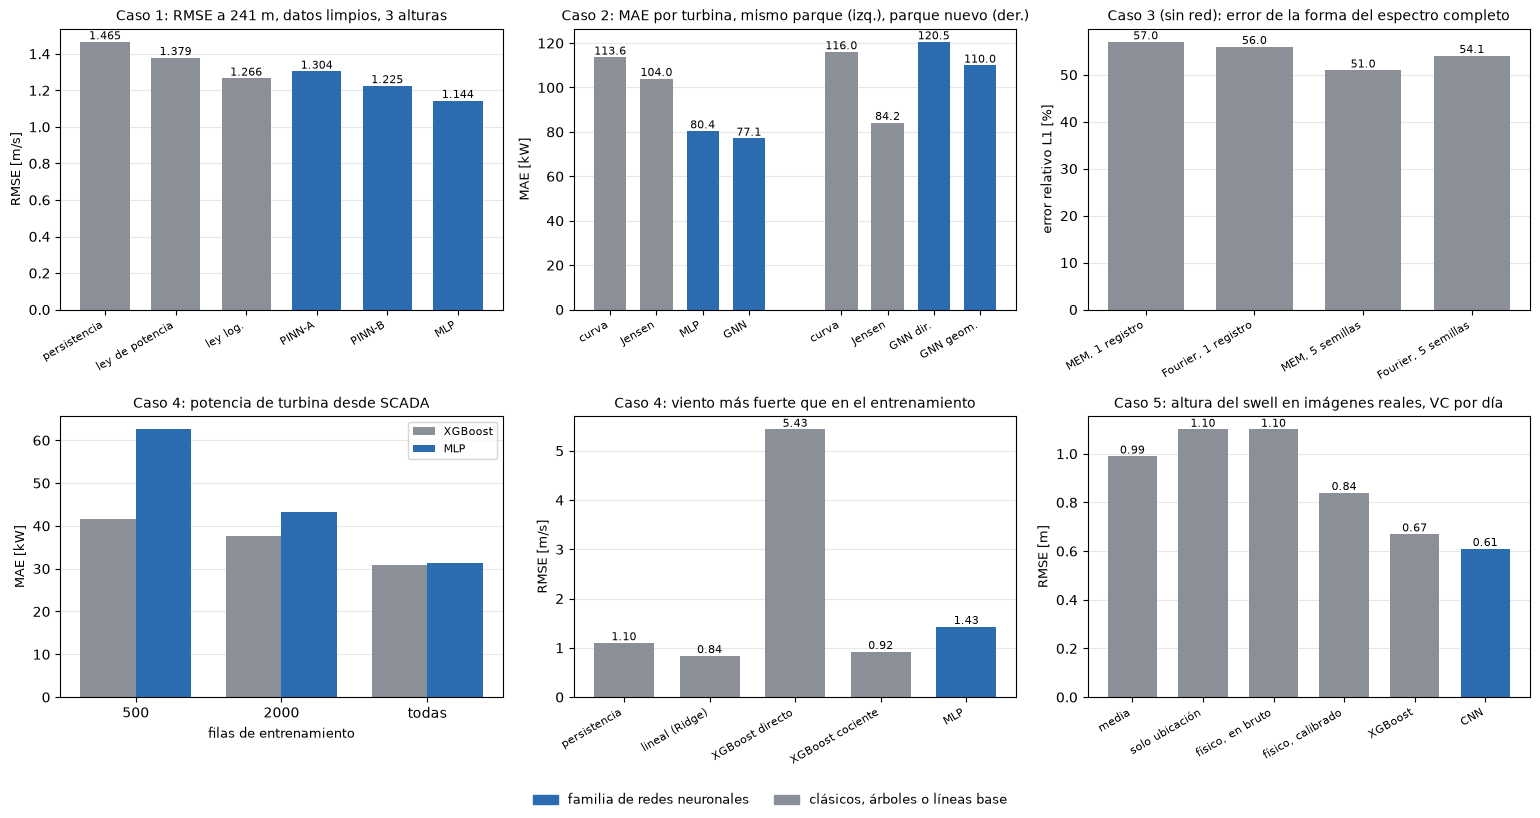

In [3]:
BLUE, GREY = "#2b6cb0", "#8a8f98"          # familia de redes neuronales frente a clásicos / árboles
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2))

def bars(ax, labels, keys, colors, title, ylabel, fmt="{:.2f}", rot=30):
    vals = [V(k) for k in keys]
    xs = np.arange(len(vals))
    ax.bar(xs, vals, color=colors, width=0.7)
    for x, v in zip(xs, vals):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(xs); ax.set_xticklabels(labels, rotation=rot, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

bars(axes[0, 0], ["persistencia", "ley de potencia", "ley log.", "PINN-A", "PINN-B", "MLP"],
     ["pinn_epl241_persist", "pinn_epl241_pow", "pinn_epl241_log", "pinn_epl241_pinna", "pinn_epl241_pinnb", "pinn_epl241_mlp"],
     [GREY, GREY, GREY, BLUE, BLUE, BLUE],
     "Caso 1: RMSE a 241 m, datos limpios, 3 alturas", "RMSE [m/s]", "{:.3f}")

# caso 2: dos grupos de barras en un panel
ax = axes[0, 1]
g1 = [("curva", "gnn_pen_curve", GREY), ("Jensen", "gnn_pen_jensen", GREY), ("MLP", "gnn_pen_mlp", BLUE), ("GNN", "gnn_pen_gnn", BLUE)]
g2 = [("curva", "gnn_kel_curve", GREY), ("Jensen", "gnn_kel_jensen", GREY), ("GNN dir.", "gnn_kel_gnn_dir", BLUE), ("GNN geom.", "gnn_kel_gnn_geom", BLUE)]
xs = list(range(len(g1))) + [len(g1) + 1 + i for i in range(len(g2))]
for x, (lab, k, c) in zip(xs, g1 + g2):
    ax.bar(x, V(k), color=c, width=0.7); ax.text(x, V(k), f"{V(k):.1f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels([g[0] for g in g1 + g2], rotation=30, ha="right", fontsize=8)
ax.set_title("Caso 2: MAE por turbina, mismo parque (izq.), parque nuevo (der.)", fontsize=10); ax.set_ylabel("MAE [kW]", fontsize=9)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

bars(axes[0, 2], ["MEM, 1 registro", "Fourier, 1 registro", "MEM, 5 semillas", "Fourier, 5 semillas"],
     ["wave_L1_mem", "wave_L1_four", "wave_L1_mem5", "wave_L1_four5"], [GREY] * 4,
     "Caso 3 (sin red): error de la forma del espectro completo", "error relativo L1 [%]", "{:.1f}")

# caso 4: datos tabulares, extremos de la curva de aprendizaje y fuera de rango
ax = axes[1, 0]
rowsx = [("500", "xgb_n500_xgb", "xgb_n500_mlp"), ("2000", "xgb_n2000_xgb", "xgb_n2000_mlp"), ("todas", "xgb_nall_xgb", "xgb_nall_mlp")]
x = np.arange(len(rowsx)); w = 0.38
ax.bar(x - w / 2, [V(r[1]) for r in rowsx], w, color=GREY, label="XGBoost")
ax.bar(x + w / 2, [V(r[2]) for r in rowsx], w, color=BLUE, label="MLP")
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rowsx]); ax.set_xlabel("filas de entrenamiento", fontsize=9)
ax.set_title("Caso 4: potencia de turbina desde SCADA", fontsize=10); ax.set_ylabel("MAE [kW]", fontsize=9)
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

bars(axes[1, 1], ["persistencia", "lineal (Ridge)", "XGBoost directo", "XGBoost cociente", "MLP"],
     ["xgb_oor_persist", "xgb_oor_ridge", "xgb_oor_xgb", "xgb_oor_ratio", "xgb_oor_mlp"],
     [GREY, GREY, GREY, GREY, BLUE], "Caso 4: viento más fuerte que en el entrenamiento", "RMSE [m/s]", "{:.2f}")

bars(axes[1, 2], ["media", "solo ubicación", "físico, en bruto", "físico, calibrado", "XGBoost", "CNN"],
     ["cnn_hs_mean", "cnn_hs_meta", "cnn_phys_rmse", "cnn_hs_cal", "cnn_hs_xgb", "cnn_hs_cnn"],
     [GREY, GREY, GREY, GREY, GREY, BLUE], "Caso 5: altura del swell en imágenes reales, VC por día", "RMSE [m]", "{:.2f}")

fig.legend(handles=[Patch(color=BLUE, label="familia de redes neuronales"), Patch(color=GREY, label="clásicos, árboles o líneas base")],
           loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Lectura.** En cada panel las barras salen directamente de los cuadernos. Menos es mejor. El caso 1 muestra que el MLP simple, y no las redes informadas por la física, lideró con datos limpios; el caso 2 muestra la inversión cuando el parque es nuevo; el caso 3 recuerda que dos reconstrucciones clásicas pueden fallar ambas en aproximadamente la mitad de la forma; el caso 4 muestra al árbol ganando en una tabla y fallando fuera de rango, donde lo hacen mejor un modelo lineal y un árbol con un buen objetivo; el caso 5 muestra a la red y a los árboles empatados, ambos muy por delante de la física en bruto y de la media. El color es una etiqueta de familia (red o no), no un veredicto. Son estudios únicos con pocos sitios y semillas: léelos como evidencia sobre *mecanismos*, no como clasificaciones que se repetirán en otro sitio.

## 9. Lecciones transversales

1. **Primero las líneas base, y fuertes.** La persistencia, una ley logarítmica, un modelo de Jensen ajustado, el predictor de la media y XGBoost fueron los rivales. En el caso 5 la media fue la línea base que el método físico en bruto no superó (1,10 m frente a 0,99 m). En el caso 2, un modelo de un parámetro superó a una red cuando la física era simple. Una red que solo se compara con una línea base débil no demuestra nada.
2. **La validación honesta se ajusta al uso.** Meses posteriores para prever, otro parque para la transferencia, otro rango de altura para la extrapolación y **días completos fuera** para imágenes que ven el mismo temporal (86 días, no 187 imágenes). Una partición aleatoria habría halagado a todos los modelos de estos cuadernos. La variación entre semillas, el número de muestras independientes y el "esto es un piloto" se indican donde corresponde.
3. **La física es un conocimiento previo, no un oráculo.** Ayudó como regularizador (caso 1, datos escasos y ruidosos), como condición de contorno (velocidad cero en la superficie) y como forma de elegir el objetivo (el cociente de cizalladura en el caso 4). Costó un 65 % donde la ecuación no se cumplía (caso 1, colina). La cantidad de física es una decisión de diseño con una perilla ($\lambda$) que necesita validación.
4. **Etiquetas, no arquitectura.** En el caso 5 el piloto con 8 imágenes dio una CNN que no aprendió nada, y con 187 imágenes etiquetadas redujo el error de altura un 38 % frente a la media. En el caso 2 los **rasgos de arista** y la **diversidad de parques** importaron más que la atención frente a la agregación por suma. Compara con el módulo 13 de este curso.
5. **Controles que pueden fallar.** Un modelo solo de ubicación que no debe superar a la media; una propiedad aleatoria que una sonda no debe predecir; un banco sintético con verdad conocida donde la respuesta se sabe; una referencia "con ventaja" (un lidar alto) para mostrar que la información que falta no está en los datos (caso 1). Un resultado que nunca se ha expuesto a un control es un resultado en el que aún no puedes confiar.
6. **Informa de los negativos y del coste.** Cada cuaderno tiene una sección que enumera lo que falló, y se informa del coste (17 s frente a 156 s de entrenamiento en el caso 4). Un modelo que gana por un 2 % y es nueve veces más barato de mantener es una decisión distinta de uno que gana por un 2 % y es nueve veces más caro.
7. **Saber lo que el modelo no puede hacer.** Ninguna de estas redes extrapoló; ninguna recuperó la estabilidad atmosférica desde tres alturas ruidosas; ninguna dio una dirección a partir de una sola imagen de intensidad sin información adicional. Dilo, y propón la medición que lo arreglaría.

## 10. Ampliar cada caso con los módulos más nuevos

Son **sugerencias de trabajo extra**, no resultados: ninguna se ejecutó en los cuadernos (los ejercicios de los propios cuadernos enumeran algunas).

| Caso | Ampliación | Módulo |
|---|---|---|
| 1 PINN | Un operador neuronal que aprenda el perfil como función de la altura *y* de la estabilidad con muchos perfiles, en vez de una red por perfil. | [09, aprendizaje automático científico](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| | Intervalos conformales o de conjunto alrededor de la velocidad extrapolada, porque un número sin intervalo oculta cuán incierta es la velocidad en lo alto. | [11, incertidumbre](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| | Medir qué entradas usa la red global, como hizo la sonda lineal en el caso 5. | [10, interpretabilidad](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| 2 GNN | Las propuestas "guiadas por la física" del propio cuaderno: el déficit de Jensen como rasgo de arista, una salida residual alrededor de Jensen, un término de estela en la pérdida; no probadas aquí. | [08, redes de grafos](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| | Preentrenar con muchos parques y adaptar unos pocos pesos por parque nuevo (ajuste fino, adaptadores) en vez de reentrenar. | [02, ajuste fino](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| | Intervalos para el total del parque, que es lo que oferta un operador. | [11, incertidumbre](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| 3 Espectros de oleaje | Un autocodificador para comprimir o limpiar espectros; un estimador aprendido de la distribución direccional entrenado con verdad simulada. | [04, autocodificadores](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| 4 XGBoost frente a PyTorch | Modelos de series temporales e híbridos (árboles para horizontes cortos, una red para los largos); previsiones por cuantiles. | [07 de 1001](https://neural-networks.academy.forwardforecasting.eu/es/07-series-temporales/) y [11](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |
| 5 CNN con radar | Preentrenar con un gran archivo de imágenes de radar sin etiquetar mediante autosupervisión y ajustar con las 187 etiquetadas; un método de incertidumbre para los extremos subestimados; un segundo sitio y una boya como referencia independiente. | [04, aprendizaje autosupervisado](https://neural-networks-1002.academy.forwardforecasting.eu/es/), [11, incertidumbre](https://neural-networks-1002.academy.forwardforecasting.eu/es/), [13, IA centrada en los datos](https://neural-networks-1002.academy.forwardforecasting.eu/es/) |

Para agentes que ejecuten estas comparaciones de forma automática, mira el curso hermano de [sistemas RAG](https://rag-systems.academy.forwardforecasting.eu/es/), en particular los [agentes con LangGraph](https://rag-systems.academy.forwardforecasting.eu/es/05-agentes-con-langgraph/).

## 11. Límites y licencias

**Límites de la evidencia.**

* **Pocos sitios, registros cortos, conjuntos de test pequeños.** Un parque y un año en la mayor parte del caso 4; un sitio del Pacífico sur y un año en el caso 5; 400 perfiles de test y una sola realización de ruido en la primera parte del caso 1; dos parques reales en el caso 2. Las diferencias de unos pocos por ciento entre métodos están dentro del ruido de semilla y de muestreo, y los cuadernos lo dicen.
* **Los bancos sintéticos muestran mecanismos, no porcentajes reales.** Los simuladores de los casos 2 y 5 contienen la física que les pusimos. Un buen número en un simulador es coherencia con el simulador.
* **ERA5 no es la verdad de referencia.** Es un reanálisis, un modelo de olas que asimila medidas, y puede compartir errores con lo que aprende la red. No hay ninguna boya cerca del sitio del caso 5.
* **La validación agrupada por día deja 86 días independientes.** La diferencia entre la CNN y XGBoost no es concluyente.
* **Leer números entre cuadernos.** Los cuadernos usan la coma decimal española en el texto y el punto decimal en las tablas impresas; en algún sitio la prosa redondea un valor algo distinto de la tabla. Este módulo cita la tabla cuando difieren.
* **Ninguna afirmación sobre rendimiento operativo.** Nada de esto es un producto validado de previsión o de estimación de cargas.

**Licencias de los datos (leer antes de reutilizar o publicar).**

| Datos | Dónde se usan | Licencia o condiciones |
|---|---|---|
| Extractos de lidar marino de las dos plataformas y el faro (de un portal neerlandés de mediciones de viento marino) | caso 1 | **Sin licencia explícita declarada.** Se usan aquí con fines docentes citando la fuente; consulta las condiciones del portal antes de cualquier uso comercial o redistribución |
| Conjunto abierto del parque eólico de Altahullion, [doi:10.5281/zenodo.19948235](https://doi.org/10.5281/zenodo.19948235) | caso 1 | CC BY 4.0 (atribución) |
| SCADA de Penmanshiel y Kelmarsh, [doi:10.5281/zenodo.5946808](https://doi.org/10.5281/zenodo.5946808), [doi:10.5281/zenodo.5841834](https://doi.org/10.5281/zenodo.5841834) (Plumley, 2022) | casos 2 y 4 | CC BY 4.0 (atribución) |
| Extracto de imágenes de radar TenGeoP-SARwv, [doi:10.17882/56796](https://doi.org/10.17882/56796) (Wang y otros, 2019, derivado de datos Copernicus Sentinel-1) | casos 3 y 5 | **CC BY-NC-SA 4.0: solo uso no comercial, y el material derivado debe compartirse con la misma licencia** |
| Espectros derivados de radar de 187 imágenes de 2016 (`sar_sitio_2016_espectros.npz`, sin las imágenes) y 8 imágenes de enero de 2016 (`sar_sitio_2016.npz`) | caso 5 | **La misma licencia, CC BY-NC-SA 4.0: no comercial** |
| Valores de ERA5 interpolados a las imágenes, [doi:10.1002/qj.3803](https://doi.org/10.1002/qj.3803) (Hersbach y otros, 2020; Servicio de Cambio Climático de Copernicus) | caso 5 | Licencia de Copernicus, con atribución |
| Centro Nacional de Datos de Boyas de NOAA, estación 46042, [página de la estación](https://www.ndbc.noaa.gov/station_page.php?station=46042) | caso 3 | datos públicos |

El texto y el código de los cuadernos son del curso; **los datos conservan la licencia de su origen, y varios son de uso no comercial.** Si planeas un trabajo comercial, tienes que obtener de nuevo los datos con condiciones que lo permitan.

## 12. Ideas clave, ejercicios y referencias

**Ideas clave**

* La pregunta nunca es "red o no", sino **en qué condiciones** gana la red. Cinco problemas reales dieron una respuesta coherente: gana con entradas estructuradas (grafos, imágenes) con suficiente diversidad o etiquetas reales, con muchas salidas relacionadas y como modelo regularizado por la física con datos escasos o ruidosos; empata o pierde con datos tabulares pequeños, frente a un modelo simple bien especificado y fuera del rango en que se entrenó.
* **La física es un regularizador y una condición de contorno**, valiosa donde se cumple y costosa donde no (un 65 % peor en la colina).
* **La generalización viene de la diversidad**: una red entrenada con un parque aprendió ese parque (59,4 kW en parques nuevos frente a 30,7 kW en el suyo).
* **Las etiquetas vencen a la arquitectura** (CNN y XGBoost empataron una vez usadas las etiquetas de un reanálisis).
* **Valida como vas a usar**, incluye controles que puedan fallar e informa de los negativos y del coste.
* **Atiende a las licencias**: varios de los datos son de uso no comercial.

**Ejercicios**

1. Abre el cuaderno 01 y cambia el peso $\lambda$ para la primera plataforma marina con ruido, como propone su ejercicio 1. ¿Dónde está el óptimo y se mueve con el ruido?
2. En el cuaderno 02, sección 20, añade una tercera ventana de ajuste fino de dos meses. ¿Dónde cruza la red preentrenada al modelo de Jensen ajustado?
3. En el cuaderno 04, implementa el híbrido sugerido en su conclusión (XGBoost hasta 1 hora, MLP después). ¿Cuánto baja el error medio y cuánto cuesta mantenerlo?
4. En el cuaderno 05, usa los 86 días de la sección 6.5 para calcular un intervalo de confianza por *bootstrap* (remuestreando días) de la diferencia de RMSE de altura entre la CNN y XGBoost. ¿Incluye el cero?
5. Elige un resultado de este módulo que te sorprenda y anota (a) la línea base con la que se comparó, (b) la partición de validación, (c) el control que podría haber mostrado que era un artefacto y (d) el coste. ¿Cuál de los cuatro es el más débil?
6. Elige un problema propio (de cualquier sector) y rellena la fila de la tabla de la sección 1: problema, datos, tecnologías, ganador, lección. Decide de antemano qué te haría decir que la red perdió.

**Referencias** (cada enlace se abrió y el título, los autores y el año se comprobaron con la página de destino o el registro DOI)

* Raissi, M., Perdikaris, P. y Karniadakis, G. E. (2019). Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. *Journal of Computational Physics* 378, 686-707: https://doi.org/10.1016/j.jcp.2018.10.045
* Foken, T. (2006). 50 years of the Monin-Obukhov similarity theory. *Boundary-Layer Meteorology* 119, 431-447: https://doi.org/10.1007/s10546-006-9048-6
* Jensen, N. O. (1983). A note on wind generator interaction. Risoe-M-2411, Risoe National Laboratory: https://orbit.dtu.dk/en/publications/a-note-on-wind-generator-interaction
* Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O. y Dahl, G. E. (2017). Neural message passing for quantum chemistry. ICML. arXiv:1704.01212: https://arxiv.org/abs/1704.01212
* Battaglia, P. W. y otros (2018). Relational inductive biases, deep learning, and graph networks. arXiv:1806.01261: https://arxiv.org/abs/1806.01261
* Plumley, C. (2022). Penmanshiel wind farm data: https://doi.org/10.5281/zenodo.5946808 . Kelmarsh wind farm data: https://doi.org/10.5281/zenodo.5841834 (ambos CC BY 4.0).
* Lygre, A. y Krogstad, H. E. (1986). Maximum entropy estimation of the directional distribution in ocean wave spectra. *Journal of Physical Oceanography* 16(12), 2052-2060: https://doi.org/10.1175/1520-0485(1986)016%3C2052:MEEOTD%3E2.0.CO;2
* Alpers, W. R., Ross, D. B. y Rufenach, C. L. (1981). On the detectability of ocean surface waves by real and synthetic aperture radar. *Journal of Geophysical Research* 86(C7), 6481-6498: https://doi.org/10.1029/JC086iC07p06481
* Hasselmann, K. y Hasselmann, S. (1991). On the nonlinear mapping of an ocean wave spectrum into a synthetic aperture radar image spectrum and its inversion. *Journal of Geophysical Research* 96(C6), 10713-10729: https://doi.org/10.1029/91JC00302
* Wang, C., Mouche, A., Tandeo, P. y otros (2019). A labelled ocean SAR imagery dataset of ten geophysical phenomena from Sentinel-1 wave mode. *Geoscience Data Journal* 6(2), 105-115: https://doi.org/10.1002/gdj3.73 . Datos: https://doi.org/10.17882/56796 (CC BY-NC-SA 4.0).
* Hersbach, H. y otros (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society* 146(730), 1999-2049: https://doi.org/10.1002/qj.3803 . Datos: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels
* Chen, T. y Guestrin, C. (2016). XGBoost: a scalable tree boosting system. KDD, 785-794: https://doi.org/10.1145/2939672.2939785 , arXiv:1603.02754: https://arxiv.org/abs/1603.02754
* Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on tabular data? NeurIPS Datasets and Benchmarks. arXiv:2207.08815: https://arxiv.org/abs/2207.08815
* Centro Nacional de Datos de Boyas de NOAA, estación 46042: https://www.ndbc.noaa.gov/station_page.php?station=46042

In [4]:
print(f"{len(QUOTED)} números citados, todos verificados con los cinco cuadernos de wind_cases/")

188 números citados, todos verificados con los cinco cuadernos de wind_cases/
